In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns
import re
import json

In [2]:
df_train_raw = pd.read_json("train.jsonl", lines=True)
df_test_raw  = pd.read_json("test.jsonl",  lines=True)

We will be working on the English dataset.

# 1. Data Exploration and Cleaning

In [3]:
def basic_exploratory_analysis(df, name):
    print(f"\n=== {name} ===")
    print("Rows:", len(df))
    print("Fields:", df.columns)

    print("\nLabel counts:")
    print(df["label"].value_counts(dropna=False))

    # "Empty" here includes empty strings in addition to NaN
    premise_empty = df["premise"].astype(str).str.strip().eq("")
    print("\nPremise empty by label:")                          
    print(pd.crosstab(df["label"], premise_empty))

    # Duplicates (exact same premise & hypopthesis & label)
    dup_mask = df.duplicated(subset=["premise", "hypothesis", "label"])
    print("\nDuplicate rows (premise+hypothesis+label):", dup_mask.sum())

    # Length stats (word counts)
    tmp = df.copy()
    tmp["premise_words"] = tmp["premise"].astype(str).str.split().str.len()
    tmp["hypothesis_words"] = tmp["hypothesis"].astype(str).str.split().str.len()
    print("\nLength stats (number of words):")
    print(tmp[["premise_words", "hypothesis_words"]].describe().loc[["mean","50%","max"]])

Let us analyze the raw dataset.

In [4]:
basic_exploratory_analysis(df_train_raw, "Train (raw)")
basic_exploratory_analysis(df_test_raw,  "Test (raw)")


=== Train (raw) ===
Rows: 7191
Fields: Index(['doc_id', 'key', 'premise', 'hypothesis', 'label'], dtype='object')

Label counts:
label
Entailment       3530
NotMentioned     2820
Contradiction     841
Name: count, dtype: int64

Premise empty by label:
premise        False  True 
label                      
Contradiction    841      0
Entailment      3530      0
NotMentioned       0   2820

Duplicate rows (premise+hypothesis+label): 2882

Length stats (number of words):
      premise_words  hypothesis_words
mean      44.050341         12.823529
50%       34.000000         13.000000
max      424.000000         23.000000

=== Test (raw) ===
Rows: 2091
Fields: Index(['doc_id', 'key', 'premise', 'hypothesis', 'label'], dtype='object')

Label counts:
label
Entailment       968
NotMentioned     903
Contradiction    220
Name: count, dtype: int64

Premise empty by label:
premise        False  True 
label                      
Contradiction    220      0
Entailment       968      0
NotMentioned

We observed that all instances labeled **NotMentioned** have an empty premise, which we treat as missing evidence rather than a meaningful textual input. Including these would incentivize the model to learn a shortcut (detecting an empty string), and would not aid in learning the linguistic patterns of contradiction. Therefore, we drop the instances with the **NotMentioned** label and only keep the **Contradiction** and **Entailment** labels.

In [5]:
df_train = df_train_raw[df_train_raw["label"] != "NotMentioned"].reset_index(drop=True)
df_test  = df_test_raw[df_test_raw["label"]  != "NotMentioned"].reset_index(drop=True)

Now, let us look at the result.

In [6]:
basic_exploratory_analysis(df_train, "Train (cleaned)")
basic_exploratory_analysis(df_test,  "Test (cleaned)")


=== Train (cleaned) ===
Rows: 4371
Fields: Index(['doc_id', 'key', 'premise', 'hypothesis', 'label'], dtype='object')

Label counts:
label
Entailment       3530
Contradiction     841
Name: count, dtype: int64

Premise empty by label:
premise        False
label               
Contradiction    841
Entailment      3530

Duplicate rows (premise+hypothesis+label): 79

Length stats (number of words):
      premise_words  hypothesis_words
mean      72.469915         12.975978
50%       59.000000         13.000000
max      424.000000         23.000000

=== Test (cleaned) ===
Rows: 1188
Fields: Index(['doc_id', 'key', 'premise', 'hypothesis', 'label'], dtype='object')

Label counts:
label
Entailment       968
Contradiction    220
Name: count, dtype: int64

Premise empty by label:
premise        False
label               
Contradiction    220
Entailment       968

Duplicate rows (premise+hypothesis+label): 23

Length stats (number of words):
      premise_words  hypothesis_words
mean           

After removing **NotMentioned**, we found a small number of duplicate text pairs (approx. 2%). We deduplicate the training set to avoid over-weighting repeated examples.

In [8]:
df_train = df_train.drop_duplicates(subset=["premise", "hypothesis", "label"]).reset_index(drop=True)

print("Train rows (dedup):", len(df_train))
print("Test rows (raw):", len(df_test))

Train rows (dedup): 4292
Test rows (raw): 1188


We already have the train and test sets. We keep the provided test set untouched for final evaluation. From the provided training set, we create a validation set using a stratified split to preserve the label distribution. The training portion is used to fit the models, while the validation set is used for model selection and hyperparameter tuning. The test set is used only for final reporting.

In [9]:
df_train, df_val = train_test_split(df_train, test_size=0.20, stratify=df_train["label"], random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

To build a traditional machine learning baseline, we first prefix each token with p_ or h_ to preserve whether it comes from the premise or the hypothesis. Then we concatenate the two segments into a single input string, separated by a special marker (\_\_sep\_\_). Finally, we transform the text into TF-IDF features vectors. The vectorizer is fit on the training split only, and the same fitted transformation is applied to the validation and test splits.

In [10]:
def prefix_text(series, prefix):
    return series.fillna("").astype(str).map(lambda s: " ".join(f"{prefix}{w}" for w in s.split()))

prem_train = prefix_text(df_train["premise"], "p_")
hypo_train = prefix_text(df_train["hypothesis"], "h_")
prem_val   = prefix_text(df_val["premise"], "p_")
hypo_val   = prefix_text(df_val["hypothesis"], "h_")
prem_test  = prefix_text(df_test["premise"], "p_")
hypo_test  = prefix_text(df_test["hypothesis"], "h_")

vec = TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=2)

X_train_vec = vec.fit_transform(prem_train + " __sep__ " + hypo_train)
X_val_vec   = vec.transform(prem_val + " __sep__ " + hypo_val)
X_test_vec  = vec.transform(prem_test + " __sep__ " + hypo_test)

y_train = df_train["label"].values
y_val   = df_val["label"].values
y_test  = df_test["label"].values

print(X_train_vec.shape, X_val_vec.shape, X_test_vec.shape)

(3433, 24325) (859, 24325) (1188, 24325)


### Data presentation and visualization

This section provides a short visual overview of the dataset that we will be working with.

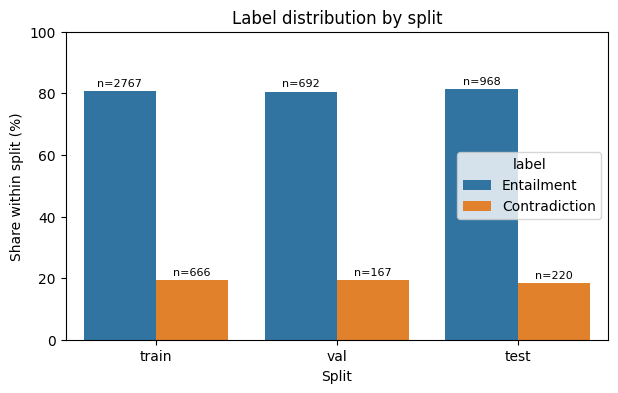

In [12]:
df_all = pd.concat([df_train.assign(split="train"), df_val.assign(split="val"), df_test.assign(split="test")], ignore_index=True)

label_order = ["Entailment", "Contradiction"]
split_order = ["train", "val", "test"]

counts = (df_all.groupby(["split", "label"]).size().reset_index(name="count"))
counts["share_pct"] = counts["count"] / counts.groupby("split")["count"].transform("sum") * 100

counts["split"] = pd.Categorical(counts["split"], categories=split_order, ordered=True)
counts["label"] = pd.Categorical(counts["label"], categories=label_order, ordered=True)
counts = counts.sort_values(["label", "split"])

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=counts, x="split", y="share_pct", hue="label", order=split_order, hue_order=label_order)
ax.set_xlabel("Split")
ax.set_ylabel("Share within split (%)")
ax.set_title("Label distribution by split")
ax.set_ylim(0, 100)

for patch, (_, row) in zip(ax.patches, counts.iterrows()):  # annotate bars with raw counts
    ax.annotate(
        f"n={int(row['count'])}",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center",
        va="bottom",
        fontsize=8,
        xytext=(0, 2),
        textcoords="offset points",
    )

plt.show()

We can see that the train/validation/test splits preserve a very similar class balance: in each split, Entailment makes up ~80% of examples and Contradiction ~20%. This indicates the stratified split worked as intended and helps ensure that validation/test performance is comparable to training conditions.

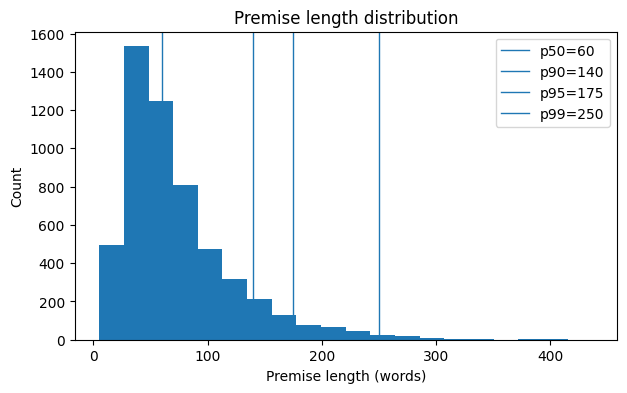

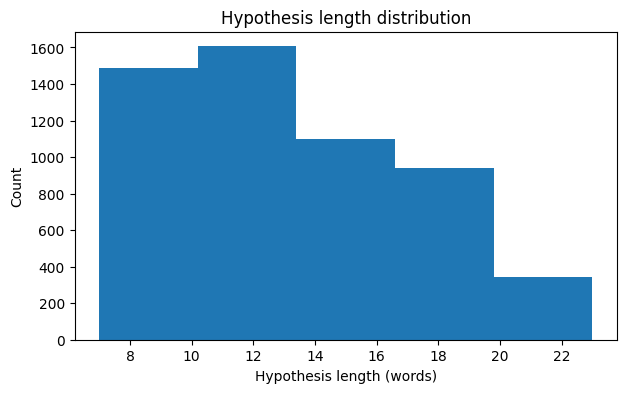

In [13]:
def word_count(s):
    s = "" if pd.isna(s) else str(s)
    return len(re.findall(r"\w+", s))

df_all["premise_wc"] = df_all["premise"].apply(word_count)
df_all["hypothesis_wc"] = df_all["hypothesis"].apply(word_count)

percentiles = [50, 90, 95, 99]
pvals = np.percentile(df_all["premise_wc"], percentiles)

plt.figure(figsize=(7, 4))
plt.hist(df_all["premise_wc"], bins=20)
plt.xlabel("Premise length (words)")
plt.ylabel("Count")
plt.title("Premise length distribution")
for p, v in zip(percentiles, pvals):    # percentile lines
    plt.axvline(v, linewidth=1, label=f"p{p}={int(v)}")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(df_all["hypothesis_wc"], bins=5)
plt.xlabel("Hypothesis length (words)")
plt.ylabel("Count")
plt.title("Hypothesis length distribution")
plt.show()

Premises are substantially longer and more variable than hypotheses. The premise length distribution is right-skewed, with most premises clustered around ~50–100 words and a long tail of very long sections, a few reaching 400+ words. In contrast, hypotheses are short and tightly concentrated (roughly 7–23 words, peaking around 10–13), so we focus further analysis on premises. 

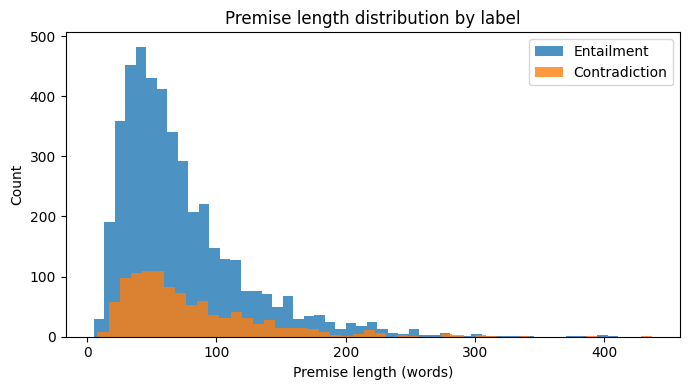

In [14]:
plt.figure(figsize=(7, 4))
for label in ["Entailment", "Contradiction"]:
    subset = df_all.loc[df_all["label"] == label, "premise_wc"]
    plt.hist(subset, bins=50, alpha=0.8, label=label)

plt.xlabel("Premise length (words)")
plt.ylabel("Count")
plt.title("Premise length distribution by label")
plt.legend()
plt.tight_layout()
plt.show()

Both classes follow a similar right-skewed length distribution. Contradiction premises are slightly shorter on average, but the overlap is large, so length alone is not a useful separator between labels.

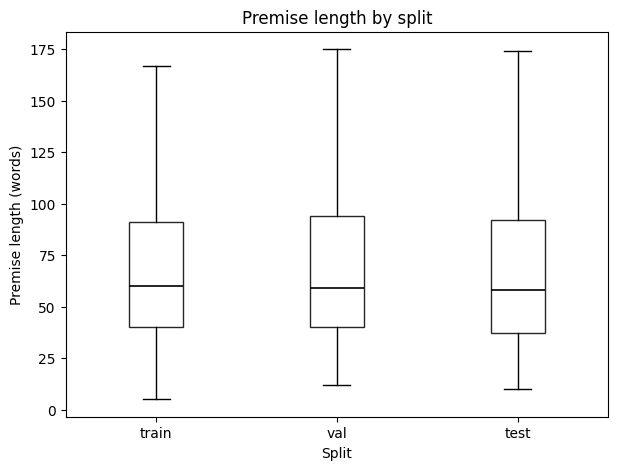

In [15]:
data_by_split = [df_all.loc[df_all["split"] == s, "premise_wc"].values for s in split_order]

plt.figure(figsize=(7, 5))
bp = plt.boxplot(data_by_split, tick_labels=split_order, showfliers=False, patch_artist=True)

for box in bp["boxes"]:
    box.set_facecolor("white")
    box.set_alpha(0.85)

for med in bp["medians"]:
    med.set_color("black")
    med.set_linewidth(1.2)

plt.xlabel("Split")
plt.ylabel("Premise length (words)")
plt.title("Premise length by split")
plt.show()

The boxplots show very similar median and IQR across train/val/test, indicating the splits are consistent in terms of premise length.

Below are examples of contradicting text sections.

In [153]:
print(f"Premise: {df_train.iloc[1678]["premise"]}\nHypothesis: {df_train.iloc[1678]["hypothesis"]}\nLabel: {df_train.iloc[1678]["label"]}")

Premise: The receiving Party shall not disclose or communicate Confidential Information to any third party, except as herein provided.
Hypothesis: Receiving Party may share some Confidential Information with some third-parties (including consultants, agents and professional advisors).
Label: Contradiction


In [154]:
print(f"Premise: {df_train.iloc[450]["premise"]}\nHypothesis: {df_train.iloc[450]["hypothesis"]}\nLabel: {df_train.iloc[450]["label"]}")

Premise: 3. No copies will be made or retained of any written information without the permission of Manitoba Housing.
Hypothesis: Receiving Party may create a copy of some Confidential Information in some circumstances.
Label: Contradiction


In [155]:
print(f"Premise: {df_train.iloc[1142]["premise"]}\nHypothesis: {df_train.iloc[1142]["hypothesis"]}\nLabel: {df_train.iloc[1142]["label"]}")

Premise: Disposal means execution of reasonable measures to return or destroy all materials and copies including electronic data.
Hypothesis: Receiving Party may retain some Confidential Information even after the return or destruction of Confidential Information.
Label: Contradiction


# 2. Traditional ML Baseline

In this stage, we train several traditional machine learning classifiers for contradiction detection. We treat **Contradiction** as the positive class and use TF-IDF representation prepared in Stage 1. For each model, we tune hyperparameters using 5-fold stratified cross-validation on the training split, and pick the best configuration based on **F1 on the Contradiction class**. Finally, we evaluate the selected model once on the validation split.

In [16]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    make_scorer, accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)


scoring = {
    "f1_contradiction": make_scorer(f1_score, pos_label="Contradiction"),
    "prec_contradiction": make_scorer(precision_score, pos_label="Contradiction"),
    "rec_contradiction": make_scorer(recall_score, pos_label="Contradiction"),
    "acc": make_scorer(accuracy_score),
}

### Logistic Regression

We tune the regularization strength (`C`).

In [17]:
print("===Hyperparameter optimization (Logistic Regression)===")
params = {"C": [1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3]}
clf = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=2000
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_lr = GridSearchCV(
    estimator=clf,
    param_grid=params,
    scoring=scoring,
    refit="f1_contradiction",
    cv=skf,
    return_train_score=True,
    n_jobs=-1
)
grid_lr.fit(X_train_vec, y_train)

print("Best params:", grid_lr.best_params_)
print(f"Best mean StratifiedKFold F1 (Contradiction): {grid_lr.best_score_:.4f}")

# Result table for diff hyperparams
results = pd.DataFrame(grid_lr.cv_results_)[
    ["param_C",
     "mean_test_f1_contradiction", "std_test_f1_contradiction",
     "mean_test_prec_contradiction",
     "mean_test_rec_contradiction",
     "mean_test_acc",
     "rank_test_f1_contradiction"]
].sort_values("rank_test_f1_contradiction")
print("\nCross Validation results:")
print(results.to_string(index=False))


# Evaluation on the validation set
print("\n===Evaluation on validation set===")
best_clf = grid_lr.best_estimator_
val_pred = best_clf.predict(X_val_vec)

acc = accuracy_score(y_val, val_pred)
prec = precision_score(y_val, val_pred, pos_label="Contradiction")
rec = recall_score(y_val, val_pred, pos_label="Contradiction")
f1 = f1_score(y_val, val_pred, pos_label="Contradiction")

print("Validation metrics:")
print(f"F1:        {f1:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"Accuracy:  {acc:.4f}")

labels = ["Entailment", "Contradiction"]
cm = confusion_matrix(y_val, val_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels])
print("\nConfusion matrix")
print(cm_df)

print("\nClassification report:")
print(classification_report(y_val, val_pred, labels=labels))

===Hyperparameter optimization (Logistic Regression)===
Best params: {'C': 10.0}
Best mean StratifiedKFold F1 (Contradiction): 0.8369

Cross Validation results:
 param_C  mean_test_f1_contradiction  std_test_f1_contradiction  mean_test_prec_contradiction  mean_test_rec_contradiction  mean_test_acc  rank_test_f1_contradiction
  10.000                    0.836885                   0.026553                      0.795874                     0.882886       0.933012                           1
1000.000                    0.831619                   0.020908                      0.838585                     0.825788       0.935048                           2
 100.000                    0.826558                   0.028514                      0.811894                     0.842341       0.931264                           3
   1.000                    0.789385                   0.033643                      0.698101                     0.908394       0.905923                           4
   0.100 

### Linear SVM (LinearSVC)

We tune `C` again.

In [18]:
print("===Hyperparameter optimization (LinearSVC)===")
params = {"C": [1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3]}
clf = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_svc = GridSearchCV(
    estimator=clf,
    param_grid=params,
    scoring=scoring,
    refit="f1_contradiction",
    cv=skf,
    return_train_score=True,
    n_jobs=-1
)
grid_svc.fit(X_train_vec, y_train)

print("Best params:", grid_svc.best_params_)
print(f"Best mean StratifiedKFold F1 (Contradiction): {grid_svc.best_score_:.4f}")

# Result table for diff hyperparams
results = pd.DataFrame(grid_svc.cv_results_)[
    ["param_C",
     "mean_test_f1_contradiction", "std_test_f1_contradiction",
     "mean_test_prec_contradiction",
     "mean_test_rec_contradiction",
     "mean_test_acc",
     "rank_test_f1_contradiction"]
].sort_values("rank_test_f1_contradiction")

print("\nCross Validation results:")
print(results.to_string(index=False))

# Evaluation on the validation set
print("\n===Evaluation on validation set===")
best_clf = grid_svc.best_estimator_
val_pred = best_clf.predict(X_val_vec)

acc = accuracy_score(y_val, val_pred)
prec = precision_score(y_val, val_pred, pos_label="Contradiction")
rec = recall_score(y_val, val_pred, pos_label="Contradiction")
f1 = f1_score(y_val, val_pred, pos_label="Contradiction")

print("Validation metrics:")
print(f"F1:        {f1:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"Accuracy:  {acc:.4f}")

labels = ["Entailment", "Contradiction"]
cm = confusion_matrix(y_val, val_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels])

print("\nConfusion matrix")
print(cm_df)

print("\nClassification report:")
print(classification_report(y_val, val_pred, labels=labels))

===Hyperparameter optimization (LinearSVC)===
Best params: {'C': 10.0}
Best mean StratifiedKFold F1 (Contradiction): 0.8394

Cross Validation results:
 param_C  mean_test_f1_contradiction  std_test_f1_contradiction  mean_test_prec_contradiction  mean_test_rec_contradiction  mean_test_acc  rank_test_f1_contradiction
  10.000                    0.839356                   0.022748                      0.836662                     0.842386       0.937379                           1
   1.000                    0.830032                   0.026642                      0.794568                     0.869397       0.930681                           2
 100.000                    0.825642                   0.018931                      0.834926                     0.816844       0.933008                           3
1000.000                    0.796540                   0.023641                      0.807649                     0.786814       0.921938                           4
   0.100           

### Random Forest

We tune the number of trees (`n_estimators`), maximum tree depth (`max_depth`), number of features considered at each split (`max_features`), the minimum number of samples required to split an internal node (`min_samples_split`), and whether bootstrap sampling is used (`bootstrap`). Because the search space is large, we use RandomizedSearchCV to sample a limited number of configurations and select the best model.

In [19]:
print("===Hyperparameter optimization (RandomForest)===")
params = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20, 40, 80],
    "max_features": ["sqrt", "log2", None],
    "min_samples_split": [2, 5, 10, 20],
    "bootstrap": [True, False]
}
clf = RandomForestClassifier(
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rand_rf = RandomizedSearchCV(
    estimator=clf,
    param_distributions=params,
    n_iter=10,
    scoring=scoring,
    refit="f1_contradiction",
    cv=skf,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)
rand_rf.fit(X_train_vec, y_train)

print("Best params:", rand_rf.best_params_)
print(f"Best mean StratifiedKFold F1 (Contradiction): {rand_rf.best_score_:.4f}")

# Results table (top configs)
results = pd.DataFrame(rand_rf.cv_results_)[
    [
        "param_n_estimators",
        "param_max_depth",
        "param_max_features",
        "param_min_samples_split",
        "param_bootstrap",
        "mean_test_f1_contradiction", "std_test_f1_contradiction",
        "mean_test_prec_contradiction",
        "mean_test_rec_contradiction",
        "mean_test_acc",
        "mean_train_f1_contradiction",
        "rank_test_f1_contradiction",
    ]
].sort_values("rank_test_f1_contradiction")

print("\nCross Validation results (top 10):")
print(results.head(10).to_string(index=False))

# Evaluation on the validation set
print("\n===Evaluation on validation set===")
best_clf = rand_rf.best_estimator_
val_pred = best_clf.predict(X_val_vec)

acc = accuracy_score(y_val, val_pred)
prec = precision_score(y_val, val_pred, pos_label="Contradiction")
rec = recall_score(y_val, val_pred, pos_label="Contradiction")
f1 = f1_score(y_val, val_pred, pos_label="Contradiction")

print("Validation metrics:")
print(f"F1:        {f1:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"Accuracy:  {acc:.4f}")

labels = ["Entailment", "Contradiction"]
cm = confusion_matrix(y_val, val_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels])

print("\nConfusion matrix")
print(cm_df)

print("\nClassification report:")
print(classification_report(y_val, val_pred, labels=labels))

===Hyperparameter optimization (RandomForest)===
Best params: {'n_estimators': 400, 'min_samples_split': 10, 'max_features': None, 'max_depth': 10, 'bootstrap': False}
Best mean StratifiedKFold F1 (Contradiction): 0.8102

Cross Validation results (top 10):
 param_n_estimators param_max_depth param_max_features  param_min_samples_split  param_bootstrap  mean_test_f1_contradiction  std_test_f1_contradiction  mean_test_prec_contradiction  mean_test_rec_contradiction  mean_test_acc  mean_train_f1_contradiction  rank_test_f1_contradiction
                400              10               None                       10            False                    0.810241                   0.026012                      0.729539                     0.911402       0.917280                     0.898462                           1
                100              20               None                       20            False                    0.799469                   0.037481                      0.75

### Majority classifier

`DummyClassifier(strategy="most_frequent")` always predicts the majority class (Entailment). This provides a lower bound that any useful model should beat.

In [118]:
print("===Majority baseline (DummyClassifier: most_frequent)===")
dummy = DummyClassifier(strategy="most_frequent", random_state=42)
dummy.fit(X_train_vec, y_train)
val_pred = dummy.predict(X_val_vec)

acc = accuracy_score(y_val, val_pred)
prec = precision_score(y_val, val_pred, pos_label="Contradiction", zero_division=0)
rec = recall_score(y_val, val_pred, pos_label="Contradiction", zero_division=0)
f1 = f1_score(y_val, val_pred, pos_label="Contradiction", zero_division=0)

print("Validation metrics:")
print(f"F1:        {f1:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"Accuracy:  {acc:.4f}")

dummy_metrics = {
    "model": "Majority classifier",
    "f1_contradiction": f1,
    "precision_contradiction": prec,
    "recall_contradiction": rec,
    "accuracy": acc,
}

labels = ["Entailment", "Contradiction"]
cm = confusion_matrix(y_val, val_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels])
print("\nConfusion matrix")
print(cm_df)

print("\nClassification report:")
print(classification_report(y_val, val_pred, labels=labels, zero_division=0))

===Majority baseline (DummyClassifier: most_frequent)===
Validation metrics:
F1:        0.0000
Precision: 0.0000
Recall:    0.0000
Accuracy:  0.8056

Confusion matrix
                    pred_Entailment  pred_Contradiction
true_Entailment                 692                   0
true_Contradiction              167                   0

Classification report:
               precision    recall  f1-score   support

   Entailment       0.81      1.00      0.89       692
Contradiction       0.00      0.00      0.00       167

     accuracy                           0.81       859
    macro avg       0.40      0.50      0.45       859
 weighted avg       0.65      0.81      0.72       859



### Results summary (validation split)

We compare models using **F1 on the Contradiction class**, along with precision, recall and accuracy. Note that accuracy is less informative due to class imbalance (Entailment is the majority class), so we focus on Contradiction precision/recall/F1.

- **Logistic Regression**: F1 = **0.883**, Precision = 0.824, Recall = **0.952**, Accuracy = 0.951  
  *Very high recall (few missed contradictions) with a moderate number of false positives.*

- **LinearSVC**: F1 = 0.877, Precision = **0.841**, Recall = 0.916, Accuracy = 0.950  
  *Slightly higher precision than LR, but lower recall.*

- **Random Forest**: F1 = 0.844, Precision = 0.755, Recall = **0.958**, Accuracy = 0.931  
  *Highest recall, but precision drops.*

- **Majority baseline**: predicts only Entailment → contradiction Precision/Recall/F1 = 0, Accuracy = 0.806

Given the application (flagging potentially conflicting clauses), recall is especially important. **Logistic Regression** achieves the highest F1 while maintaining very high recall.

,f1_contradiction,precision_contradiction,recall_contradiction,accuracy
model,,,,
LogisticRegression,0.883333,0.823834,0.952096,0.951106
LinearSVC,0.876791,0.840659,0.916168,0.949942
RandomForest,0.844327,0.754717,0.958084,0.931315


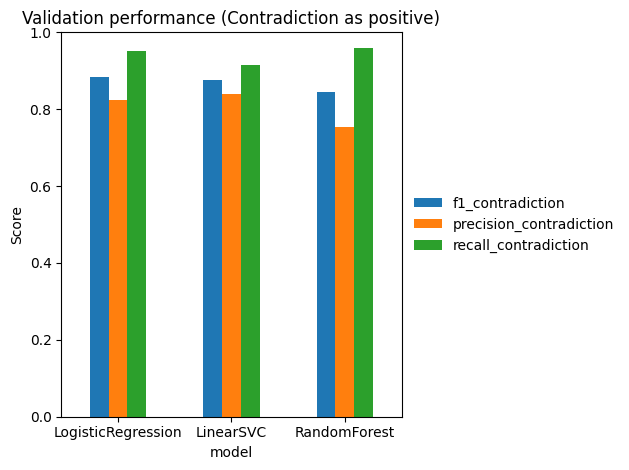

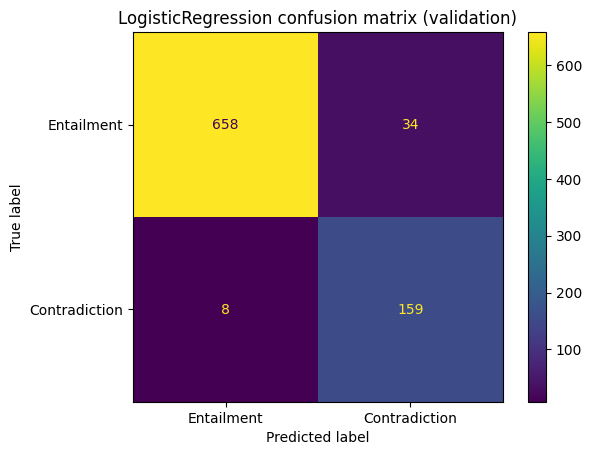

In [21]:
models = {
    "LogisticRegression": grid_lr.best_estimator_,
    "LinearSVC": grid_svc.best_estimator_,
    "RandomForest": rand_rf.best_estimator_,
}

rows = []
for name, model in models.items():
    pred = model.predict(X_val_vec)
    rows.append({
        "model": name,
        "f1_contradiction": f1_score(y_val, pred, pos_label="Contradiction", zero_division=0),
        "precision_contradiction": precision_score(y_val, pred, pos_label="Contradiction", zero_division=0),
        "recall_contradiction": recall_score(y_val, pred, pos_label="Contradiction", zero_division=0),
        "accuracy": accuracy_score(y_val, pred),
    })

df_metrics = pd.DataFrame(rows).set_index("model").sort_values("f1_contradiction", ascending=False)
display(df_metrics)

ax = df_metrics[["f1_contradiction", "precision_contradiction", "recall_contradiction"]].plot(kind="bar")
ax.set_ylabel("Score")
ax.set_title("Validation performance (Contradiction as positive)")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout()
plt.show()


best_model_name = df_metrics.index[0]
best_model = models[best_model_name]

labels = ["Entailment", "Contradiction"]
cm = confusion_matrix(y_val, best_model.predict(X_val_vec), labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(values_format="d")
plt.title(f"{best_model_name} confusion matrix (validation)")
plt.show()

Logistic Regression achieved the best validation F1 score for the Contradiction class, and also performed well on the other metrics. We therefore select it as the best traditional model for this task. Next, we refit the TF-IDF vectorizer on the combined training + validation data, retrain Logistic Regression on this combined set, and measure final performance on the test set.

Test metrics:
F1:        0.8218
Precision: 0.7626
Recall:    0.8909
Accuracy:  0.9285

Classification report:
               precision    recall  f1-score   support

   Entailment       0.97      0.94      0.96       968
Contradiction       0.76      0.89      0.82       220

     accuracy                           0.93      1188
    macro avg       0.87      0.91      0.89      1188
 weighted avg       0.94      0.93      0.93      1188



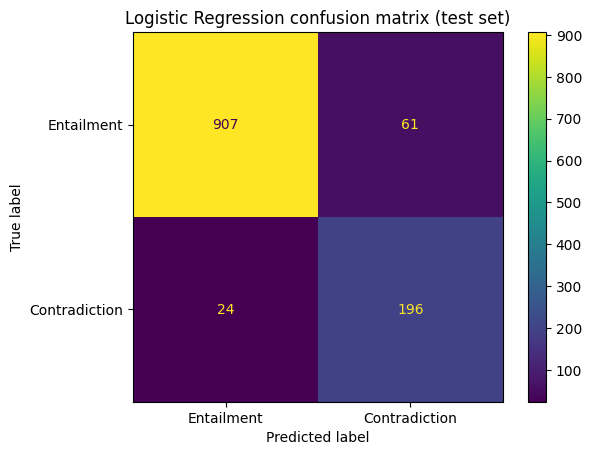

In [22]:
trainval_text = pd.concat([prem_train, prem_val], ignore_index=True) + " __sep__ " + pd.concat([hypo_train, hypo_val], ignore_index=True)
test_text = prem_test + " __sep__ " + hypo_test

vec_test = TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=2)
X_trainval = vec_test.fit_transform(trainval_text)
y_trainval = np.concatenate([y_train, y_val])
X_test     = vec_test.transform(test_text)

clf_test = LogisticRegression(C=grid_lr.best_params_["C"], class_weight="balanced", max_iter=2000, random_state=42)
clf_test.fit(X_trainval, y_trainval)

test_pred = clf_test.predict(X_test)

f1_test = f1_score(y_test, test_pred, pos_label="Contradiction")
prec_test = precision_score(y_test, test_pred, pos_label="Contradiction", zero_division=0)
rec_test = recall_score(y_test, test_pred, pos_label="Contradiction", zero_division=0)
acc_test = accuracy_score(y_test, test_pred)

print("Test metrics:")
print(f"F1:        {f1_test:.4f}")
print(f"Precision: {prec_test:.4f}")
print(f"Recall:    {rec_test:.4f}")
print(f"Accuracy:  {acc_test:.4f}")

labels = ["Entailment", "Contradiction"]
print("\nClassification report:")
print(classification_report(y_test, test_pred, labels=labels, zero_division=0))

cm_test = confusion_matrix(y_test, test_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=labels)
disp.plot(values_format="d")
plt.title(f"Logistic Regression confusion matrix (test set)")
plt.show()

task2final_metrics = {
    "model": f"Logistic Regression (C={grid_lr.best_params_["C"]})",
    "f1_contradiction": f1_test,
    "precision_contradiction": prec_test,
    "recall_contradiction": rec_test,
    "accuracy": acc_test,
    "confusion_matrix": cm_test
}

We observe a moderate drop on the test set compared to the validation set. Most of the decrease comes from an increase in both false positives and false negatives. Still, the Contradiction F1 score is ≈0.82, with recall ≈0.89, which suggests that the model generalizes reasonably well.

### Summary

We trained several traditional machine learning classifiers to detect **Contradiction** vs **Entailment** using a **TF–IDF** text representation of the (premise, hypothesis) pairs. We evaluated and tuned models on the training split with cross-validation, and compared performance on the validation split.

We tested:
- **Logistic Regression**
- **Linear SVM (LinearSVC)**
- **Random Forest**
- **Majority classifier**

**Logistic Regression** achieved the best validation performance, so we retrained it on **train + validation** and evaluated once on the **test** split to obtain the final traditional ML baseline.

# 3. Transformer Fine-Tuning

In this stage, we move from traditional ML to transformer-based models. We fine-tune several pre-trained transformer models at different parameter configurations to classify a pair of legal segments as either Contradiction or Entailment.
Because the dataset is imbalanced and the class of primary interest is **Contradiction**, we focus on **F1 / Precision / Recall for the Contradiction class**, and use accuracy mainly as a supplementary metric.

### Model selection
We experiment with two pre-trained transformer models:

- **`google-bert/bert-base-uncased`** (general-domain English BERT baseline)
- **`nlpaueb/legal-bert-base-uncased`** (BERT further pre-trained on English legal text)

The motivation for including LegalBERT is that our data contains domain-specific language and structure, such as legal terms, uncommon negation patterns, and exception structures ("unless", "except", "notwithstanding", etc.). A model trained on this style of text may capture contradiction cues better than a general model.

In [23]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, TrainingArguments, Trainer, set_seed
import datasets
from datasets import Dataset
from collections import Counter
import accelerate
from transformers.utils import logging
logging.set_verbosity_error()
import torch
fp16 = torch.cuda.is_available()
set_seed(42)

c:\Users\pusni\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [24]:
def confusion_matrix_from_metrics(n_total, n_pos, precision, recall, pos_label = 1, labels = (0, 1), rounding = "nearest", clip=True):
    if (n_total <= 0) or (n_pos < 0 or n_pos > n_total) or (not (0.0 <= precision <= 1.0) or not (0.0 <= recall <= 1.0)):
        return np.array([[-1, -1], [-1, -1]], dtype=int)

    n_neg = n_total - n_pos

    if n_pos == 0:
        tn, fp, fn, tp = n_neg, 0, 0, 0
    elif recall == 0.0:
        tp, fn = 0.0, float(n_pos)
        fp = 0.0
        tn = float(n_neg)
    else:
        tp = recall * n_pos
        fn = n_pos - tp

        if precision == 0.0:
            return np.array([[-1, -1], [-1, -1]], dtype=int)

        fp = tp * (1.0 / precision - 1.0)
        tn = n_neg - fp

    def applyRound(x):
        if rounding == "nearest":
            return int(round(x))
        if rounding == "floor":
            return int(np.floor(x))
        if rounding == "ceil":
            return int(np.ceil(x))
        

    tn_i, fp_i, fn_i, tp_i = map(applyRound, (tn, fp, fn, tp))

    if clip:
        tp_i = max(0, min(tp_i, n_pos))
        fn_i = max(0, min(fn_i, n_pos - tp_i))
        fp_i = max(0, min(fp_i, n_neg))
        tn_i = max(0, min(tn_i, n_neg - fp_i))

        pos_sum = tp_i + fn_i
        if pos_sum != n_pos:
            fn_i += (n_pos - pos_sum)
            fn_i = max(0, min(fn_i, n_pos))
        neg_sum = tn_i + fp_i
        if neg_sum != n_neg:
            tn_i += (n_neg - neg_sum)
            tn_i = max(0, min(tn_i, n_neg))

    cm = np.array([[tn_i, fp_i],
                      [fn_i, tp_i]], dtype=int)

    if labels == (0, 1):
        return cm
    elif labels == (1, 0):
        return cm[::-1, ::-1]
    return np.array([[-1, -1], [-1, -1]], dtype=int)

In [25]:
train_ds = Dataset.from_pandas(df_train[["premise", "hypothesis", "label"]].copy())
val_ds   = Dataset.from_pandas(df_val[["premise", "hypothesis", "label"]].copy())

label2id = {"Entailment": 0, "Contradiction": 1}
id2label = {0: "Entailment", 1: "Contradiction"}

def add_label_ids(batch):
    batch["labels"] = [label2id[x] for x in batch["label"]]
    return batch

train_ds = train_ds.map(add_label_ids, batched=True)
val_ds   = val_ds.map(add_label_ids, batched=True)

Map: 100%|██████████| 859/859 [00:00<00:00, 243012.76 examples/s]


After preparing the data, we pass each (premise, hypothesis) pair through the tokenizer to inspect the resulting token lengths. This helps us choose a reasonable `max_length` and estimate how often truncation will occur.

From the token length distribution, we see that most instances fall below **256 tokens**, so setting `max_length=256` keeps the majority of pairs untruncated while remaining efficient for training on our GPU.

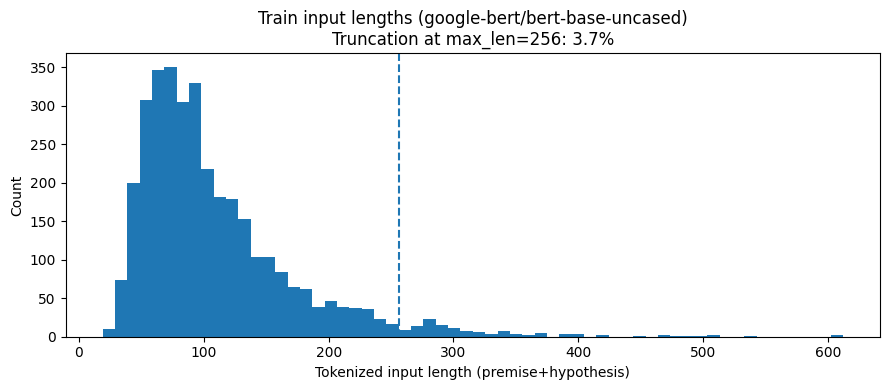

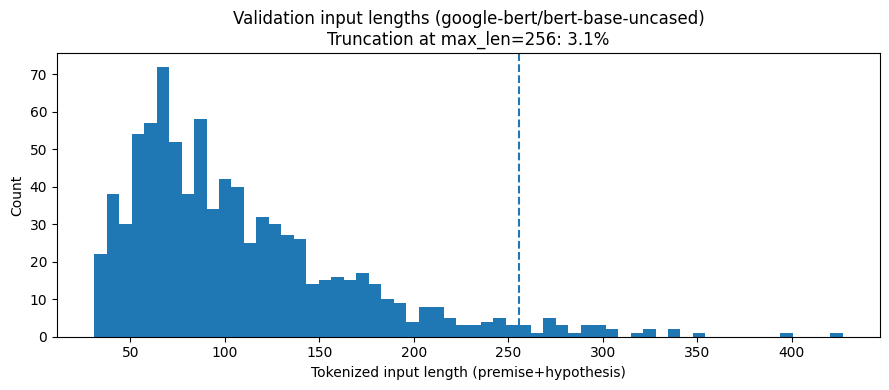

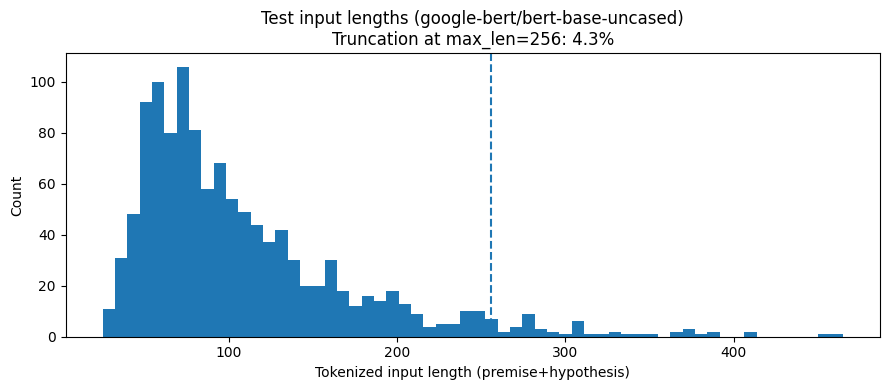

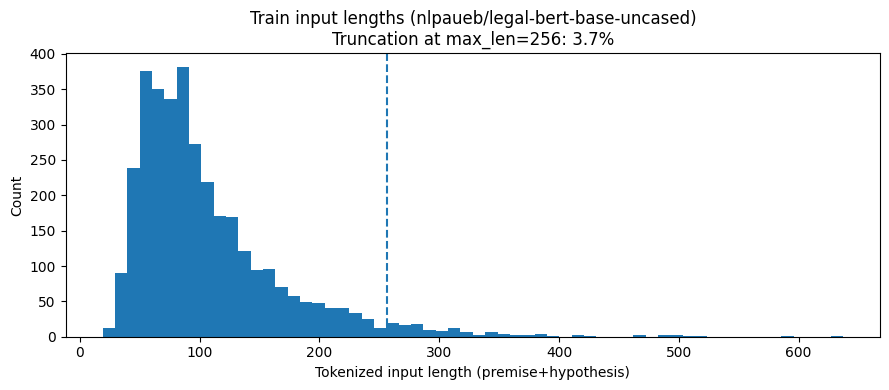

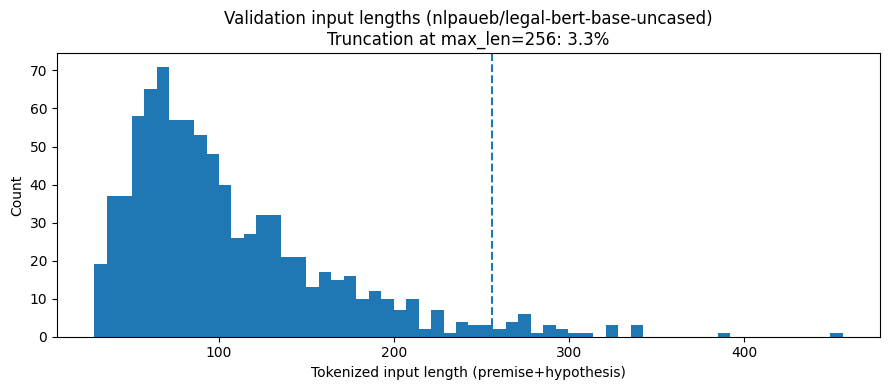

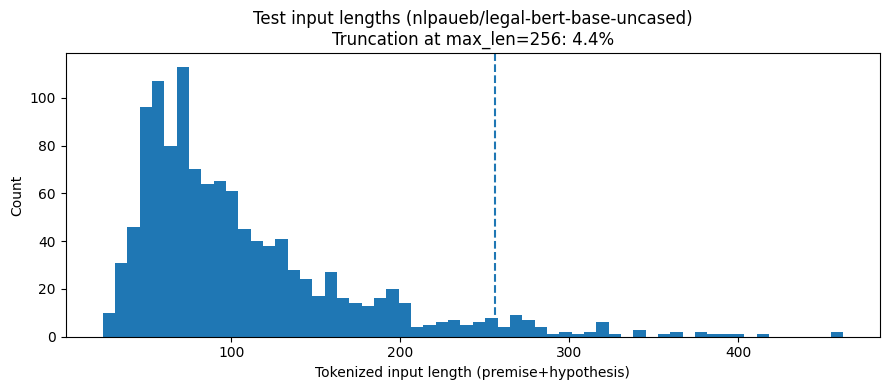

In [26]:
def analyze_pair_input_lengths(model_name, max_len=256, bins=60):
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def compute_pair_token_lengths(df):
        lengths = []
        for i in range(len(df)):
            prem = str(df["premise"].iloc[i] or "")
            hyp  = str(df["hypothesis"].iloc[i] or "")
            enc = tokenizer(prem, hyp, truncation=False, padding=False)
            lengths.append(len(enc["input_ids"]))
        return np.array(lengths, dtype=int)

    def plot_length_histogram(lengths, title):
        trunc_pct = (lengths > max_len).mean() * 100 if len(lengths) else 0.0
        plt.figure(figsize=(9, 4))
        plt.hist(lengths, bins=bins)
        plt.axvline(max_len, linestyle="--")
        plt.title(f"{title}\nTruncation at max_len={max_len}: {trunc_pct:.1f}%")
        plt.xlabel("Tokenized input length (premise+hypothesis)")
        plt.ylabel("Count")
        plt.tight_layout()
        plt.show()

    train_lengths = compute_pair_token_lengths(df_train)
    val_lengths   = compute_pair_token_lengths(df_val)
    test_lengths  = compute_pair_token_lengths(df_test)

    plot_length_histogram(train_lengths, f"Train input lengths ({model_name})")
    plot_length_histogram(val_lengths,   f"Validation input lengths ({model_name})")
    plot_length_histogram(test_lengths,  f"Test input lengths ({model_name})")



analyze_pair_input_lengths("google-bert/bert-base-uncased")
analyze_pair_input_lengths("nlpaueb/legal-bert-base-uncased")

The `run_experiment()` function implements a standard transformer fine-tuning workflow. It tokenizes both the training and evaluation splits using the model’s tokenizer, loads the pre-trained sequence classification model, defines the evaluation metrics, and configures the training run. It then fine-tunes the model and, once training completes, evaluates the fine-tuned model on the evaluation set. During training, we select the best checkpoint based on **F1 for the Contradiction class**, since Contradiction is the primary class of interest and the dataset is imbalanced. F1 provides a better summary of precision/recall trade-offs than accuracy.

In [54]:
def run_experiment(train_base, eval_base, model_name, out_dir, lr, max_len, epochs, batch_size, warmup_ratio=0.0, eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True):
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    def preprocess_function(batch):
        return tokenizer(batch["premise"], batch["hypothesis"], truncation=True, max_length=max_len)

    train_tok = train_base.map(preprocess_function, batched=True, remove_columns=["premise", "hypothesis", "label"])
    eval_tok   = eval_base.map(preprocess_function, batched=True, remove_columns=["premise", "hypothesis", "label"])

    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=2,
        label2id=label2id,
        id2label=id2label
    )

    def compute_metrics(p):
        preds = np.argmax(p.predictions, axis=1)
        labels = p.label_ids
        return {
            "f1_contradiction": f1_score(labels, preds, pos_label=1, zero_division=0),
            "precision_contradiction": precision_score(labels, preds, pos_label=1, zero_division=0),
            "recall_contradiction": recall_score(labels, preds, pos_label=1, zero_division=0),
            "accuracy": accuracy_score(labels, preds),
        }

    training_args = TrainingArguments(
        output_dir=out_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=32,
        num_train_epochs=epochs,
        weight_decay=0.01,
        warmup_ratio=warmup_ratio,
        eval_strategy=eval_strategy,
        save_strategy=save_strategy,
        load_best_model_at_end=load_best_model_at_end,
        metric_for_best_model="f1_contradiction",
        greater_is_better=True,
        fp16=fp16,
        logging_steps=50,
        seed=42,
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_tok,
        eval_dataset=eval_tok,
        tokenizer=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )

    trainer.train()
    eval_metrics = trainer.evaluate()

    return trainer, tokenizer, eval_metrics

In [19]:
def print_majority_result():
    train_labels = train_ds["labels"]
    val_labels  = val_ds["labels"]

    most_frequent_label = Counter(train_labels).most_common(1)[0][0]
    majority_preds = np.full(len(val_labels), most_frequent_label)

    print("Majority label:", most_frequent_label)
    print("Majority baseline f1_contradiction:", f1_score(val_labels, majority_preds, pos_label=1, zero_division=0))
    print("Majority baseline precision_contradiction:", precision_score(val_labels, majority_preds, pos_label=1, zero_division=0))
    print("Majority baseline recall_contradiction:", recall_score(val_labels, majority_preds, pos_label=1, zero_division=0))
    print("Majority baseline accuracy:", accuracy_score(val_labels, majority_preds))

### Validation experiments

We compare models and configurations on the validation split and select the best checkpoint based on F1 for the Contradiction class.

In [ ]:
trainer_legal, tokenizer_legal, val_metrics_legal = run_experiment(
    train_base=train_ds,
    eval_base=val_ds,
    model_name="nlpaueb/legal-bert-base-uncased",
    out_dir="./results_legalbert",
    lr=1e-5,
    max_len=256,
    epochs=3,
    batch_size=16
)

trainer_legal.save_model("./final_legalbert")
tokenizer_legal.save_pretrained("./final_legalbert")

print("Validation metrics:", val_metrics_legal)
print_majority_result()

with open("val_metrics_legal.json", "w") as f:
    json.dump({k: float(v) for k, v in val_metrics_legal.items()}, f, indent=2)

run_config_legal = {
    "model_name": "nlpaueb/legal-bert-base-uncased",
    "lr": 1e-5,
    "max_len": 256,
    "epochs": 3,
    "batch_size": 16,
    "seed": 42,
}

with open("run_config_legal.json", "w") as f:
    json.dump(run_config_legal, f, indent=2)

Map: 100%|██████████| 859/859 [00:00<00:00, 10729.68 examples/s]
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at nlpaueb/legal-bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
C:\Users\pusni\AppData\Local\Temp\ipykernel_12980\280686032.py:47: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Epoch,Training Loss,Validation Loss,F1 Contradiction,Precision Contradiction,Recall Contradiction,Accuracy
1,0.179500,0.146346,0.869081,0.812500,0.934132,0.945285
2,0.164600,0.130816,0.895184,0.849462,0.946108,0.956927
3,0.104000,0.107917,0.927114,0.903409,0.952096,0.970896


Validation metrics: {'eval_loss': 0.10791695863008499, 'eval_f1_contradiction': 0.9271137026239067, 'eval_precision_contradiction': 0.9034090909090909, 'eval_recall_contradiction': 0.9520958083832335, 'eval_accuracy': 0.9708963911525029, 'eval_runtime': 8.3926, 'eval_samples_per_second': 102.351, 'eval_steps_per_second': 3.217, 'epoch': 3.0}
Majority label: 0
Majority baseline f1_contradiction: 0.0
Majority baseline precision_contradiction: 0.0
Majority baseline recall_contradiction: 0.0
Majority baseline accuracy: 0.8055878928987195


In [ ]:
trainer_google, tokenizer_google, val_metrics_google = run_experiment(
    train_base=train_ds,
    eval_base=val_ds,
    model_name="google-bert/bert-base-uncased",
    out_dir="./results_googlebert",
    lr=1e-5,
    max_len=256,
    epochs=3,
    batch_size=16
)

trainer_google.save_model("./final_googlebert")
tokenizer_google.save_pretrained("./final_googlebert")

print("Validation metrics:", val_metrics_google)
print_majority_result()

with open("val_metrics_google.json", "w") as f:
    json.dump({k: float(v) for k, v in val_metrics_google.items()}, f, indent=2)

run_config_google = {
    "model_name": "google-bert/bert-base-uncased",
    "lr": 1e-5,
    "max_len": 256,
    "epochs": 3,
    "batch_size": 16,
    "seed": 42,
}

with open("run_config_google.json", "w") as f:
    json.dump(run_config_google, f, indent=2)

c:\Users\pusni\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\pusni\.cache\huggingface\hub\models--google-bert--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Map: 100%|██████████| 859/859 [00:00<00:00, 10166.22 examples/s]
Xet Storage is enab

Epoch,Training Loss,Validation Loss,F1 Contradiction,Precision Contradiction,Recall Contradiction,Accuracy
1,0.203700,0.161471,0.837079,0.788360,0.892216,0.932480
2,0.170800,0.136177,0.883853,0.838710,0.934132,0.952270
3,0.134100,0.152286,0.880000,0.841530,0.922156,0.951106


Validation metrics: {'eval_loss': 0.1361766755580902, 'eval_f1_contradiction': 0.8838526912181303, 'eval_precision_contradiction': 0.8387096774193549, 'eval_recall_contradiction': 0.9341317365269461, 'eval_accuracy': 0.9522700814901047, 'eval_runtime': 3.6272, 'eval_samples_per_second': 236.821, 'eval_steps_per_second': 7.444, 'epoch': 3.0}
Majority label: 0
Majority baseline f1_contradiction: 0.0
Majority baseline precision_contradiction: 0.0
Majority baseline recall_contradiction: 0.0
Majority baseline accuracy: 0.8055878928987195


In [ ]:
trainer_legal2, tokenizer_legal2, val_metrics_legal2 = run_experiment(
    train_base=train_ds,
    eval_base=val_ds,
    model_name="nlpaueb/legal-bert-base-uncased",
    out_dir="./results_legalbert2",
    lr=2e-5,
    max_len=256,
    epochs=3,
    batch_size=16,
    warmup_ratio=0.1
)

trainer_legal2.save_model("./final_legalbert2")
tokenizer_legal2.save_pretrained("./final_legalbert2")

print("Validation metrics:", val_metrics_legal2)
print_majority_result()

with open("val_metrics_legal2.json", "w") as f:
    json.dump({k: float(v) for k, v in val_metrics_legal2.items()}, f, indent=2)

run_config_legal2 = {
    "model_name": "nlpaueb/legal-bert-base-uncased",
    "lr": 2e-5,
    "max_len": 256,
    "epochs": 3,
    "batch_size": 16,
    "warmup_ratio": 0.1,
    "seed": 42,
}

with open("run_config_legal2.json", "w") as f:
    json.dump(run_config_legal2, f, indent=2)

Map: 100%|██████████| 859/859 [00:00<00:00, 10597.13 examples/s]
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at nlpaueb/legal-bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
C:\Users\pusni\AppData\Local\Temp\ipykernel_12980\4226185000.py:48: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Epoch,Training Loss,Validation Loss,F1 Contradiction,Precision Contradiction,Recall Contradiction,Accuracy
1,0.186200,0.177998,0.835655,0.781250,0.898204,0.931315
2,0.168500,0.131474,0.900302,0.908537,0.892216,0.961583
3,0.081500,0.120214,0.915452,0.892045,0.940120,0.966240


Validation metrics: {'eval_loss': 0.1202142983675003, 'eval_f1_contradiction': 0.9154518950437318, 'eval_precision_contradiction': 0.8920454545454546, 'eval_recall_contradiction': 0.9401197604790419, 'eval_accuracy': 0.9662398137369034, 'eval_runtime': 5.6067, 'eval_samples_per_second': 153.211, 'eval_steps_per_second': 4.816, 'epoch': 3.0}
Majority label: 0
Majority baseline f1_contradiction: 0.0
Majority baseline precision_contradiction: 0.0
Majority baseline recall_contradiction: 0.0
Majority baseline accuracy: 0.8055878928987195


In [52]:
trainer_legal3, tokenizer_legal3, val_metrics_legal3 = run_experiment(
    train_base=train_ds,
    eval_base=val_ds,
    model_name="nlpaueb/legal-bert-base-uncased",
    out_dir="./results_legalbert3",
    lr=1e-5,
    max_len=384,
    epochs=3,
    batch_size=4
)

trainer_legal3.save_model("./final_legalbert3")
tokenizer_legal3.save_pretrained("./final_legalbert3")

print("Validation metrics:", val_metrics_legal3)
print_majority_result()

with open("val_metrics_legal3.json", "w") as f:
    json.dump({k: float(v) for k, v in val_metrics_legal3.items()}, f, indent=2)

run_config_legal3 = {
    "model_name": "nlpaueb/legal-bert-base-uncased",
    "lr": 1e-5,
    "max_len": 384,
    "epochs": 3,
    "batch_size": 4,
    "seed": 42,
}

with open("run_config_legal3.json", "w") as f:
    json.dump(run_config_legal3, f, indent=2)

Map: 100%|██████████| 859/859 [00:00<00:00, 10839.79 examples/s]
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at nlpaueb/legal-bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
C:\Users\pusni\AppData\Local\Temp\ipykernel_12980\4226185000.py:48: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Epoch,Training Loss,Validation Loss,F1 Contradiction,Precision Contradiction,Recall Contradiction,Accuracy
1,0.221800,0.317321,0.832905,0.729730,0.970060,0.924331
2,0.258600,0.189110,0.890173,0.860335,0.922156,0.955763
3,0.099000,0.162842,0.918129,0.897143,0.940120,0.967404


Validation metrics: {'eval_loss': 0.16284187138080597, 'eval_f1_contradiction': 0.9181286549707602, 'eval_precision_contradiction': 0.8971428571428571, 'eval_recall_contradiction': 0.9401197604790419, 'eval_accuracy': 0.9674039580908033, 'eval_runtime': 15.3768, 'eval_samples_per_second': 55.863, 'eval_steps_per_second': 1.756, 'epoch': 3.0}
Majority label: 0
Majority baseline f1_contradiction: 0.0
Majority baseline precision_contradiction: 0.0
Majority baseline recall_contradiction: 0.0
Majority baseline accuracy: 0.8055878928987195


We first fine-tuned both transformer models using the same base configuration (learning rate = 1e-5, max number of tokens = 256, number of training epochs = 3, training batch size = 16). Each model was trained on the training split and evaluated on the validation split. The results are:

**LegalBERT:**
- F1 = **0.927**
- Precision = **0.903**
- Recall = **0.952**
- Accuracy = **0.971**

**BERT-base:**
- F1 = **0.884**
- Precision = **0.839**
- Recall = **0.934**
- Accuracy = **0.952**

Since LegalBERT performs better on all metrics, we continue experimentation using LegalBERT and test two additional configurations:

- Configuration A: learning rate = 2e-5 with a warm up ratio = 0.1, max number of tokens = 256, number of training epochs = 3, training batch size = 16.
- Configuration B: learning rate = 1e-5 with no warm up, max number of tokens = 384, number of training epochs = 3, training batch size = 4 (smaller batch due to increased sequence length / VRAM constraints).

The results were as follows:

**Configuration A**:
- F1 = **0.916**
- Precision = **0.892**
- Recall = **0.940**
- Accuracy = **0.966**

**Configuration B**:
- F1 = **0.918**
- Precision = **0.897**
- Recall = **0.940**
- Accuracy = **0.967**

The bar chart below summarizes validation performance across all transformer runs, using F1/precision/recall for Contradiction and overall accuracy.

,f1_contradiction,precision_contradiction,recall_contradiction,accuracy
model,,,,
"LegalBERT (lr=1e-5, L=256)",0.9271,0.9034,0.9521,0.9709
"LegalBERT (lr=1e-5, L=384, bs=4)",0.9181,0.8971,0.9401,0.9674
"LegalBERT (lr=2e-5, warmup=0.1, L=256)",0.9155,0.8920,0.9401,0.9662
"BERT-base (lr=1e-5, L=256)",0.8839,0.8387,0.9341,0.9523


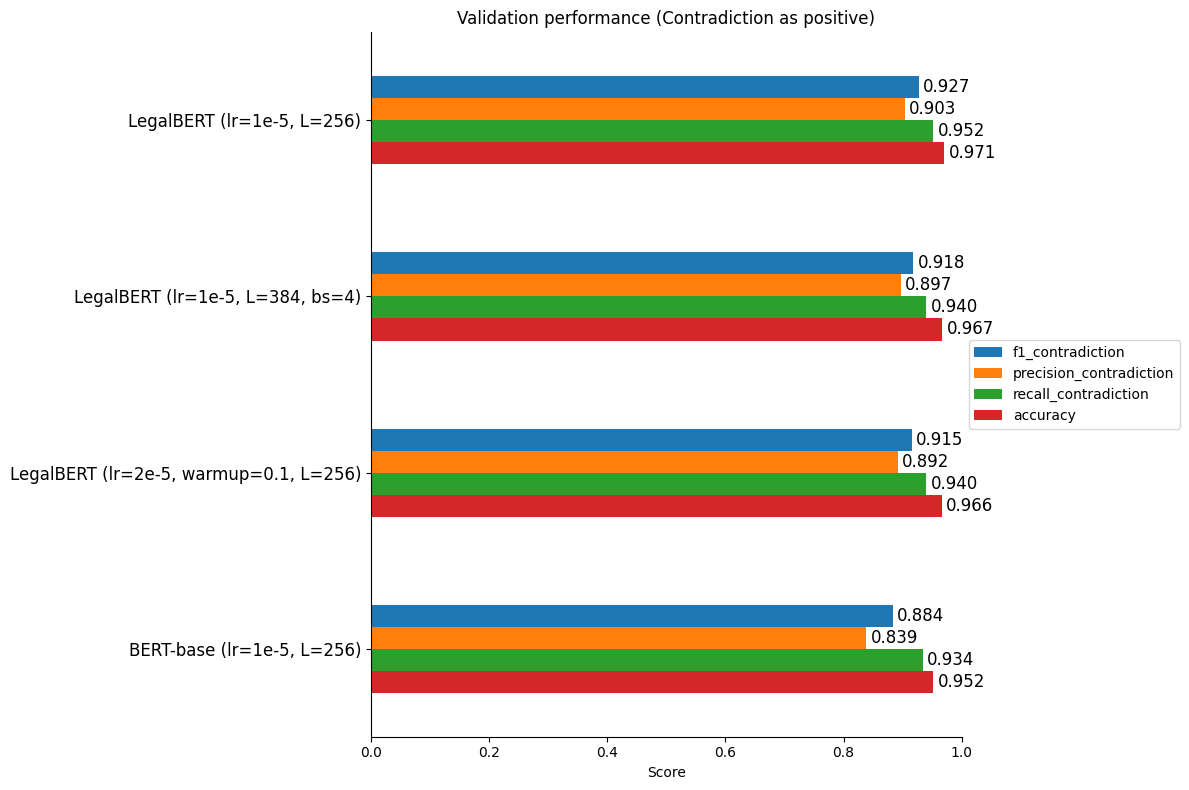

In [36]:
models = {
    "LegalBERT (lr=1e-5, L=256)": val_metrics_legal,
    "BERT-base (lr=1e-5, L=256)": val_metrics_google,
    "LegalBERT (lr=2e-5, warmup=0.1, L=256)": val_metrics_legal2,
    "LegalBERT (lr=1e-5, L=384, bs=4)": val_metrics_legal3,
}

rows = []
for name, metrics in models.items():
    rows.append({
        "model": name,
        "f1_contradiction": metrics.get("eval_f1_contradiction", None),
        "precision_contradiction": metrics.get("eval_precision_contradiction", None),
        "recall_contradiction": metrics.get("eval_recall_contradiction", None),
        "accuracy": metrics.get("eval_accuracy", None),
    })

df_metrics = (pd.DataFrame(rows).set_index("model").sort_values("f1_contradiction", ascending=False))
display(df_metrics.round(4))

fig, ax = plt.subplots(figsize=(12, 8))

df_metrics.plot(kind="barh", ax=ax)
ax.set_title("Validation performance (Contradiction as positive)")
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=12)
ax.set_xlim(0, 1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=12)
plt.tight_layout()
plt.show()

We now show the confusion matrix on the validation split for the best performing configuration.

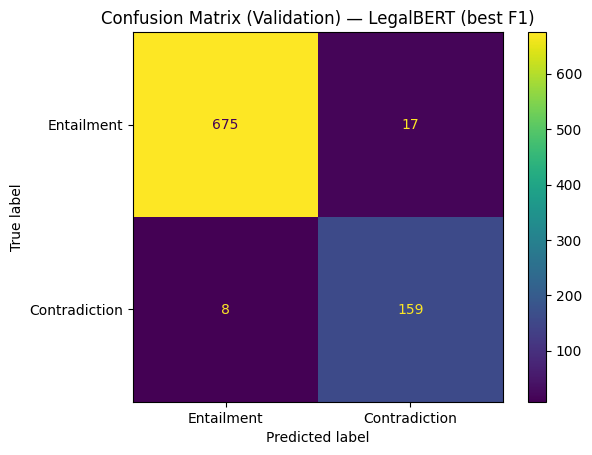

In [37]:
cm_val = confusion_matrix_from_metrics(
    n_total=val_ds.num_rows, 
    n_pos=val_ds["labels"].count(1),
    precision=val_metrics_legal["eval_precision_contradiction"],
    recall=val_metrics_legal["eval_recall_contradiction"]
)
labels = ["Entailment", "Contradiction"]
disp = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=labels)
disp.plot(values_format="d")
plt.title(f"Confusion Matrix (Validation) — LegalBERT (best F1)")
plt.show()

The model makes 17 false positives and 8 false negatives, which matches the high recall observed above.

### Final test evaluation & comparison to traditional ML

Since LegalBERT with the base configuration achieved the best validation F1, we use it as the final configuration. Next, we retrain it on train + validation and evaluate once on the test split.

In [38]:
trainval_ds = datasets.concatenate_datasets([train_ds, val_ds])
test_ds = Dataset.from_pandas(df_test[["premise", "hypothesis", "label"]].copy())

trainval_ds = trainval_ds.map(add_label_ids, batched=True)
test_ds = test_ds.map(add_label_ids, batched=True)

Map: 100%|██████████| 1188/1188 [00:00<00:00, 258177.88 examples/s]


In [56]:
trainer_test, tokenizer_test, test_metrics_test = run_experiment(
    train_base=trainval_ds,
    eval_base=test_ds,
    model_name="nlpaueb/legal-bert-base-uncased",
    out_dir="./results_test",
    lr=1e-5,
    max_len=256,
    epochs=3,
    batch_size=16,
    eval_strategy="no",
    save_strategy="no",
    load_best_model_at_end=False,
)

trainer_test.save_model("./final_test")
tokenizer_test.save_pretrained("./final_test")

print("Test metrics:", test_metrics_test)
print_majority_result()

with open("test_metrics_test.json", "w") as f:
    json.dump({k: float(v) for k, v in test_metrics_test.items()}, f, indent=2)

run_config_test = {
    "model_name": "nlpaueb/legal-bert-base-uncased",
    "lr": 1e-5,
    "max_len": 256,
    "epochs": 3,
    "batch_size": 16,
    "seed": 42,
}

with open("run_config_test.json", "w") as f:
    json.dump(run_config_test, f, indent=2)

Map: 100%|██████████| 1188/1188 [00:00<00:00, 10653.95 examples/s]
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at nlpaueb/legal-bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
C:\Users\pusni\AppData\Local\Temp\ipykernel_12980\1967977153.py:48: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Step,Training Loss
50,0.453800
100,0.304500
150,0.260100
200,0.190000
250,0.148900
300,0.168700
350,0.141000
400,0.116400
450,0.170900
500,0.139200


Test metrics: {'eval_loss': 0.1919107437133789, 'eval_f1_contradiction': 0.8597701149425288, 'eval_precision_contradiction': 0.8697674418604651, 'eval_recall_contradiction': 0.85, 'eval_accuracy': 0.9486531986531986, 'eval_runtime': 54.5981, 'eval_samples_per_second': 21.759, 'eval_steps_per_second': 0.696, 'epoch': 3.0}
Majority label: 0
Majority baseline f1_contradiction: 0.0
Majority baseline precision_contradiction: 0.0
Majority baseline recall_contradiction: 0.0
Majority baseline accuracy: 0.8055878928987195


**Final test performance (LegalBERT, learning rate = 1e-5, max number of tokens = 256, number of training epochs = 3, training batch size = 16):**
- F1(Contradiction) = **0.860**
- Precision = **0.870**
- Recall = **0.850**
- Accuracy = **0.949**

We observe a drop in performance compared to the validation results (best validation F1 = 0.927). This is expected, since the test split is fully held out and may contain slightly different contradiction patterns than the validation split.

For comparison, the performance of the best traditional ML model from Stage 2 on the same test split was:

**Logistic Regression (C = 10.0):**
- F1(Contradiction) = **0.822**
- Precision = **0.763**
- Recall = **0.891**
- Accuracy = **0.928**

Overall, LegalBERT improves the contradiction F1 and precision over the TF-IDF baseline, while Logistic Regression achieves slightly higher recall. This means that the transformer is better at reducing false alarms, whereas the linear model tends to flag more potential contradictions.


The bar chart below summarizes test set performance for the best transformer model compared to the best traditional ML model.

,f1_contradiction,precision_contradiction,recall_contradiction,accuracy
model,,,,
"LegalBERT (lr=1e-5, L=256)",0.859770,0.869767,0.850000,0.948653
Logistic Regression (C=10.0),0.821803,0.762646,0.890909,0.928451


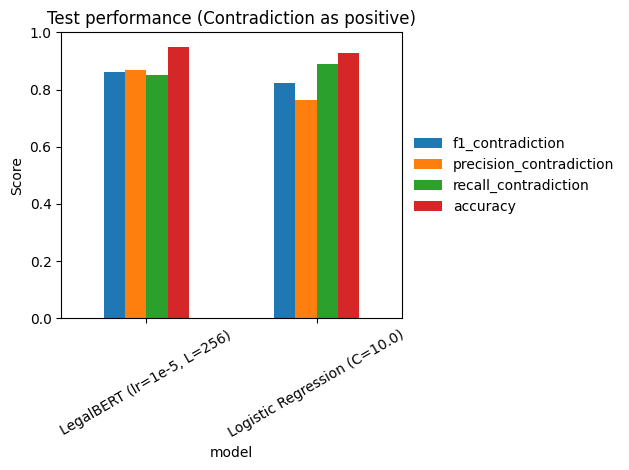

In [39]:
metrics_t3 = {
    "model": "LegalBERT (lr=1e-5, L=256)",
    "f1_contradiction": test_metrics_test.get("eval_f1_contradiction", None),
    "precision_contradiction": test_metrics_test.get("eval_precision_contradiction", None),
    "recall_contradiction": test_metrics_test.get("eval_recall_contradiction", None),
    "accuracy": test_metrics_test.get("eval_accuracy", None)
}

metrics_t2 = task2final_metrics.copy()
metrics_t2.pop("confusion_matrix", None)

rows = [
    metrics_t2,
    metrics_t3
]

df_metrics = pd.DataFrame(rows).set_index("model")
df_metrics = df_metrics.sort_values("f1_contradiction", ascending=False)

display(df_metrics)

ax = df_metrics[["f1_contradiction", "precision_contradiction", "recall_contradiction", "accuracy"]].plot(
    kind="bar"
)
ax.set_ylabel("Score")
ax.set_title("Test performance (Contradiction as positive)")
ax.set_ylim(0, 1)
plt.xticks(rotation=30)
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout()
plt.show()

We also report the confusion matrix on the test split for the final LegalBERT model.

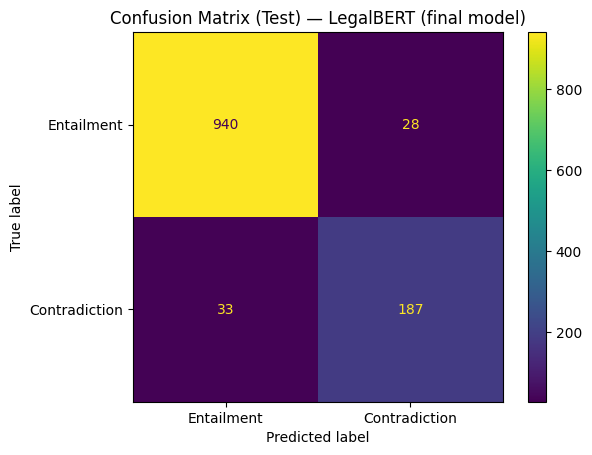

In [107]:
cm_test = confusion_matrix_from_metrics(
    n_total=test_ds.num_rows, 
    n_pos=test_ds["labels"].count(1),
    precision=test_metrics_test["eval_precision_contradiction"],
    recall=test_metrics_test["eval_recall_contradiction"]
)
labels = ["Entailment", "Contradiction"]
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=labels)
disp.plot(values_format="d")
plt.title(f"Confusion Matrix (Test) — LegalBERT (final model)")
plt.show()

task3final_metrics = {
    "model": "LegalBERT (lr=1e-5, L=256)",
    "f1_contradiction": test_metrics_test.get("eval_f1_contradiction", None),
    "precision_contradiction": test_metrics_test.get("eval_precision_contradiction", None),
    "recall_contradiction": test_metrics_test.get("eval_recall_contradiction", None),
    "accuracy": test_metrics_test.get("eval_accuracy", None),
    "confusion_matrix": cm_test
}

### Summary

We fine-tuned transformer models to classify (premise, hypothesis) pairs as **Contradiction** or **Entailment**, using **F1 for the Contradiction class** as the primary metric due to class imbalance.

We compared **BERT-base** and **LegalBERT** on the validation split. **LegalBERT** performed best, so we selected it and tested two additional configurations (warmup/higher LR and longer max_length), which did not improve validation performance.

We then retrained the selected LegalBERT configuration on **train + validation** and evaluated once on the **test** split. Compared to the best traditional baseline (**Logistic Regression**), the transformer improves contradiction F1 and precision, while Logistic Regression achieves slightly higher recall.

# 4. Sentence-Embedding Retrieval

In this stage, we train a sentence transformer model to generate embeddings for legal sections. The goal is to learn an embedding space where **sections that contradict each other have high cosine similarity**, which enables us to implement a retrieval approach that, given a new text section, retrieves the top *k* most similar (and potentially contradicting) sections from the dataset. Additionally, we use the final classifier from Stage 3 as a post-filter to identify which retrieved candidates are most likely to be true contradictions.

In [41]:
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer
from sentence_transformers.losses import ContrastiveLoss, OnlineContrastiveLoss
from sentence_transformers.evaluation import BinaryClassificationEvaluator
from sentence_transformers.training_args import SentenceTransformerTrainingArguments
from sentence_transformers import util
from datasets import concatenate_datasets

### Sentence transformer training and evaluation

Before training, we prepare the dataset in the format expected by the sentence transformers training API. The loss function expects binary labels (0/1). We map **Contradiction → 1** and **Entailment → 0** so that contradiction pairs are treated as the positive class, to match our goal of contradiction pairs having high cosine similarity in embedding space.

In [42]:
mapping = {"Contradiction": 1, "Entailment": 0}

def make_st_dataset(df):
    return Dataset.from_dict({
        "sentence1": df["hypothesis"].astype(str).tolist(),
        "sentence2": df["premise"].astype(str).tolist(),
        "label": df["label"].map(mapping).astype(int).tolist()
    })

train_st = make_st_dataset(df_train)
val_st   = make_st_dataset(df_val)
trainval_st = concatenate_datasets([train_st, val_st])
test_st  = make_st_dataset(df_test)

The `train_sentence_transformer()` function implements a standard workflow for fine-tuning a sentence transformer model. It loads a pre-trained model (we use `sentence-transformers/all-MiniLM-L6-v2`). We train the model using `ContrastiveLoss`, where labels are interpreted as (0/1) similarity targets. Contradiction (1) pairs are pushed to have higher cosine similarity, while Entailment (0) pairs are pushed apart. For evaluation, we use `BinaryClassificationEvaluator`, which computes cosine similarities between the two sentence embeddings, searches for an optimal similarity threshold, and reports metrics such as accuracy, F1, precision, and recall.

In [ ]:
def train_sentence_transformer(
        train_set,
        eval_set,
        lr, 
        epochs,
        model_name="all-MiniLM-L6-v2",
        num="",
        eval_strategy = "steps",
        save_strategy = "steps",
        eval_steps = 200,
        save_steps = 200
    ):

    model = SentenceTransformer(f"sentence-transformers/{model_name}")
    model.max_seq_length = 256
    loss = ContrastiveLoss(model)

    if eval_strategy != "no":
        pair_eval = BinaryClassificationEvaluator(
            sentences1=eval_set["sentence1"],
            sentences2=eval_set["sentence2"],
            labels=eval_set["label"],
            name="eval-pairs",
            show_progress_bar=True
        )
        eval_dataset = eval_set
        evaluator = pair_eval
    else:
        pair_eval = None
        eval_dataset = None
        evaluator = None

    args = dict(    
        output_dir=f"models/{model_name}{num}",
        num_train_epochs=epochs,
        per_device_train_batch_size=32,
        per_device_eval_batch_size=32,
        learning_rate=lr,
        warmup_ratio=0.1,
        fp16=torch.cuda.is_available(),
        eval_strategy=eval_strategy,
        save_strategy=save_strategy,
        save_total_limit=1,
        logging_steps=50
    )

    if eval_strategy != "no":
        args["eval_steps"] = eval_steps
    if save_strategy != "no":
        args["save_steps"] = save_steps

    args = SentenceTransformerTrainingArguments(**args)

    trainer = SentenceTransformerTrainer(
        model=model,
        args=args,
        train_dataset=train_set,
        eval_dataset=eval_dataset,
        loss=loss,
        evaluator=evaluator
    )

    trainer.train()

    final_metrics = None
    if eval_set is not None:
        final_eval = BinaryClassificationEvaluator(
            sentences1=eval_set["sentence1"],
            sentences2=eval_set["sentence2"],
            labels=eval_set["label"],
            name="final-eval",
            show_progress_bar=True
        )
        final_metrics = final_eval(model)
        print(final_metrics)

    return model, final_metrics

We compare multiple fine-tuning configurations on the validation split and select the best setup based on **cosine F1** from the `BinaryClassificationEvaluator` (with Contradiction as the positive class).

In [70]:
model_val1, pair_eval_val1 = train_sentence_transformer(train_set=train_st, eval_set=val_st, lr=2e-5, epochs=2, num="1")
model_val1.save("val_sentence_embedder1")

{'loss': 0.0182, 'grad_norm': 0.1276252418756485, 'learning_rate': 1.7216494845360827e-05, 'epoch': 0.46296296296296297}
{'loss': 0.0089, 'grad_norm': 0.0823780968785286, 'learning_rate': 1.2061855670103093e-05, 'epoch': 0.9259259259259259}
{'loss': 0.0077, 'grad_norm': 0.13748057186603546, 'learning_rate': 6.907216494845361e-06, 'epoch': 1.3888888888888888}
{'loss': 0.0078, 'grad_norm': 0.11062745004892349, 'learning_rate': 1.7525773195876288e-06, 'epoch': 1.8518518518518519}


Batches: 100%|██████████| 27/27 [00:00<00:00, 64.17it/s]


{'eval_loss': 0.006927057169377804, 'eval_eval-pairs_cosine_accuracy': 0.9429569266589057, 'eval_eval-pairs_cosine_accuracy_threshold': 0.7888306379318237, 'eval_eval-pairs_cosine_f1': 0.851963746223565, 'eval_eval-pairs_cosine_f1_threshold': 0.7847590446472168, 'eval_eval-pairs_cosine_precision': 0.8597560975609756, 'eval_eval-pairs_cosine_recall': 0.844311377245509, 'eval_eval-pairs_cosine_ap': 0.8862496771926214, 'eval_eval-pairs_cosine_mcc': 0.8166907587099989, 'eval_runtime': 1.8852, 'eval_samples_per_second': 455.652, 'eval_steps_per_second': 14.322, 'epoch': 1.8518518518518519}
{'train_runtime': 25.6848, 'train_samples_per_second': 267.317, 'train_steps_per_second': 8.41, 'train_loss': 0.010471272178822093, 'epoch': 2.0}


Batches: 100%|██████████| 27/27 [00:00<00:00, 62.53it/s]


{'final-eval_cosine_accuracy': 0.9441210710128056, 'final-eval_cosine_accuracy_threshold': 0.7895132303237915, 'final-eval_cosine_f1': 0.8527607361963191, 'final-eval_cosine_f1_threshold': 0.7895132303237915, 'final-eval_cosine_precision': 0.8742138364779874, 'final-eval_cosine_recall': 0.8323353293413174, 'final-eval_cosine_ap': 0.8869257651990888, 'final-eval_cosine_mcc': 0.8186790713327088}


In [71]:
model_val2, pair_eval_val2 = train_sentence_transformer(train_set=train_st, eval_set=val_st, lr=2e-5, epochs=3, num="2")
model_val2.save("val_sentence_embedder2")

{'loss': 0.0193, 'grad_norm': 0.1341370791196823, 'learning_rate': 1.8900343642611686e-05, 'epoch': 0.46296296296296297}
{'loss': 0.009, 'grad_norm': 0.08319131284952164, 'learning_rate': 1.5463917525773197e-05, 'epoch': 0.9259259259259259}
{'loss': 0.0078, 'grad_norm': 0.12334340810775757, 'learning_rate': 1.2027491408934708e-05, 'epoch': 1.3888888888888888}
{'loss': 0.0075, 'grad_norm': 0.0999007374048233, 'learning_rate': 8.591065292096221e-06, 'epoch': 1.8518518518518519}


Batches: 100%|██████████| 27/27 [00:00<00:00, 60.68it/s]


{'eval_loss': 0.006202822085469961, 'eval_eval-pairs_cosine_accuracy': 0.9511059371362048, 'eval_eval-pairs_cosine_accuracy_threshold': 0.7661938667297363, 'eval_eval-pairs_cosine_f1': 0.8708708708708709, 'eval_eval-pairs_cosine_f1_threshold': 0.7479175925254822, 'eval_eval-pairs_cosine_precision': 0.8734939759036144, 'eval_eval-pairs_cosine_recall': 0.8682634730538922, 'eval_eval-pairs_cosine_ap': 0.9016121490321473, 'eval_eval-pairs_cosine_mcc': 0.8398301134171916, 'eval_runtime': 1.9561, 'eval_samples_per_second': 439.142, 'eval_steps_per_second': 13.803, 'epoch': 1.8518518518518519}
{'loss': 0.0066, 'grad_norm': 0.20545151829719543, 'learning_rate': 5.154639175257732e-06, 'epoch': 2.314814814814815}
{'loss': 0.0062, 'grad_norm': 0.16577363014221191, 'learning_rate': 1.718213058419244e-06, 'epoch': 2.7777777777777777}
{'train_runtime': 37.9843, 'train_samples_per_second': 271.138, 'train_steps_per_second': 8.53, 'train_loss': 0.00916296492020289, 'epoch': 3.0}


Batches: 100%|██████████| 27/27 [00:00<00:00, 59.68it/s]


{'final-eval_cosine_accuracy': 0.9511059371362048, 'final-eval_cosine_accuracy_threshold': 0.7631775140762329, 'final-eval_cosine_f1': 0.8716417910447762, 'final-eval_cosine_f1_threshold': 0.734557032585144, 'final-eval_cosine_precision': 0.8690476190476191, 'final-eval_cosine_recall': 0.874251497005988, 'final-eval_cosine_ap': 0.9094191439770326, 'final-eval_cosine_mcc': 0.8405560847917432}


In [72]:
model_val3, pair_eval_val3 = train_sentence_transformer(train_set=train_st, eval_set=val_st, lr=3e-5, epochs=2, num="3")
model_val3.save("val_sentence_embedder3")

{'loss': 0.0169, 'grad_norm': 0.11195307970046997, 'learning_rate': 2.582474226804124e-05, 'epoch': 0.46296296296296297}
{'loss': 0.0081, 'grad_norm': 0.08010770380496979, 'learning_rate': 1.8092783505154638e-05, 'epoch': 0.9259259259259259}
{'loss': 0.0071, 'grad_norm': 0.12054529041051865, 'learning_rate': 1.0360824742268041e-05, 'epoch': 1.3888888888888888}
{'loss': 0.0067, 'grad_norm': 0.09021533280611038, 'learning_rate': 2.6288659793814434e-06, 'epoch': 1.8518518518518519}


Batches: 100%|██████████| 27/27 [00:00<00:00, 64.74it/s]


{'eval_loss': 0.005880344659090042, 'eval_eval-pairs_cosine_accuracy': 0.9487776484284052, 'eval_eval-pairs_cosine_accuracy_threshold': 0.7764241695404053, 'eval_eval-pairs_cosine_f1': 0.8674698795180722, 'eval_eval-pairs_cosine_f1_threshold': 0.7660483717918396, 'eval_eval-pairs_cosine_precision': 0.8727272727272727, 'eval_eval-pairs_cosine_recall': 0.8622754491017964, 'eval_eval-pairs_cosine_ap': 0.9062031290488418, 'eval_eval-pairs_cosine_mcc': 0.8357485753422302, 'eval_runtime': 1.9771, 'eval_samples_per_second': 434.481, 'eval_steps_per_second': 13.657, 'epoch': 1.8518518518518519}
{'train_runtime': 25.9726, 'train_samples_per_second': 264.356, 'train_steps_per_second': 8.316, 'train_loss': 0.009462089898685614, 'epoch': 2.0}


Batches: 100%|██████████| 27/27 [00:00<00:00, 66.43it/s]


{'final-eval_cosine_accuracy': 0.9499417927823051, 'final-eval_cosine_accuracy_threshold': 0.7804625034332275, 'final-eval_cosine_f1': 0.8693009118541033, 'final-eval_cosine_f1_threshold': 0.7804625034332275, 'final-eval_cosine_precision': 0.8827160493827161, 'final-eval_cosine_recall': 0.8562874251497006, 'final-eval_cosine_ap': 0.907058547442189, 'final-eval_cosine_mcc': 0.8385003654941532}


We trained three configurations on the training split and evaluated on the validation split:

- **Configuration 1:** learning rate = 2e-5, epochs = 2, warm up ratio = 0.1, batch size = 32
- **Configuration 2:** learning rate = 2e-5, epochs = 3, warm up ratio = 0.1, batch size = 32
- **Configuration 3:** learning rate = 3e-5, epochs = 2, warm up ratio = 0.1, batch size = 32

The validation results are:

**Configuration 1:**
- cosine F1 = **0.853**
- precision = **0.874**
- recall = **0.832**
- accuracy = **0.944**
- average precision = **0.887**

**Configuration 2:**
- cosine F1 = **0.872**
- precision = **0.869**
- recall = **0.874**
- accuracy = **0.951**
- average precision = **0.909**

**Configuration 3:**
- cosine F1 = **0.869**
- precision = **0.883**
- recall = **0.856**
- accuracy = **0.950**
- average precision = **0.907**

Configuration 2 achieved the highest validation cosine F1, so we use it as the final configuration. Next, we retrain the sentence-transformer on **train + validation** and evaluate once on the fully held-out test split

In [73]:
model_test, pair_eval_test = train_sentence_transformer(
    train_set=trainval_st,
    eval_set=test_st,
    lr=2e-5,
    epochs=3,
    eval_strategy = "no",
    save_strategy = "no",
)
model_test.save("test_sentence_embedder")

{'loss': 0.0192, 'grad_norm': 0.1211015060544014, 'learning_rate': 1.9560439560439563e-05, 'epoch': 0.37037037037037035}
{'loss': 0.0108, 'grad_norm': 0.1344284862279892, 'learning_rate': 1.6813186813186814e-05, 'epoch': 0.7407407407407407}
{'loss': 0.008, 'grad_norm': 0.16400858759880066, 'learning_rate': 1.4065934065934068e-05, 'epoch': 1.1111111111111112}
{'loss': 0.0063, 'grad_norm': 0.08355559408664703, 'learning_rate': 1.131868131868132e-05, 'epoch': 1.4814814814814814}
{'loss': 0.0067, 'grad_norm': 0.0841527208685875, 'learning_rate': 8.571428571428571e-06, 'epoch': 1.8518518518518519}
{'loss': 0.0058, 'grad_norm': 0.079520583152771, 'learning_rate': 5.824175824175825e-06, 'epoch': 2.2222222222222223}
{'loss': 0.0048, 'grad_norm': 0.06309077888727188, 'learning_rate': 3.0769230769230774e-06, 'epoch': 2.5925925925925926}
{'loss': 0.0057, 'grad_norm': 0.07519522309303284, 'learning_rate': 3.296703296703297e-07, 'epoch': 2.962962962962963}
{'train_runtime': 40.9729, 'train_samples_

Batches: 100%|██████████| 38/38 [00:00<00:00, 66.21it/s]


{'final-eval_cosine_accuracy': 0.9385521885521886, 'final-eval_cosine_accuracy_threshold': 0.7686913013458252, 'final-eval_cosine_f1': 0.8306264501160092, 'final-eval_cosine_f1_threshold': 0.7686913013458252, 'final-eval_cosine_precision': 0.8483412322274881, 'final-eval_cosine_recall': 0.8136363636363636, 'final-eval_cosine_ap': 0.8800580009355241, 'final-eval_cosine_mcc': 0.7933724245195716}


**Final test performance (lr = 2e-5, epochs = 3):**
- cosine F1 = **0.831**
- precision = **0.848**
- recall = **0.814**
- accuracy = **0.939**
- average precision = **0.880**

As in Tasks 2 and 3, we observe a drop compared to the validation results. This is expected because the test split is fully held out and may contain slightly different contradiction patterns than the validation split.

Below is a side by side bar plot of the pairwise cosine evaluation results on the test set.

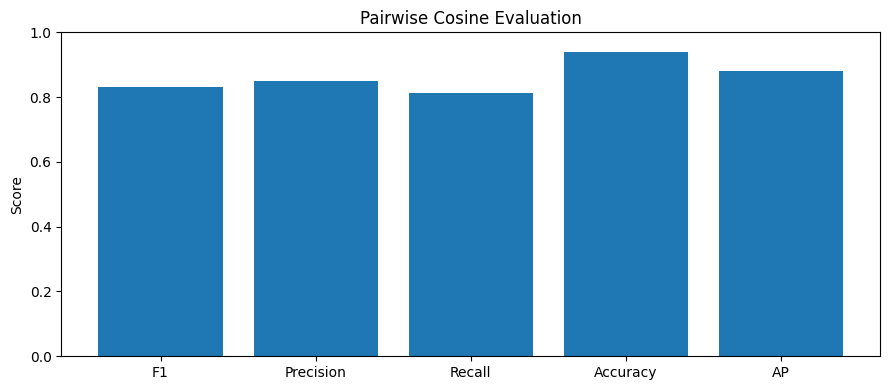

In [110]:
task4final_metrics = {
    "model": "all-MiniLM-L6-v2 (lr=2e-5, epochs=3)",
    "f1_contradiction": 0.8306264501160092,
    "precision_contradiction": 0.8483412322274881,
    "recall_contradiction": 0.8136363636363636,
    "accuracy": 0.9385521885521886,
    "average_precision": 0.8800580009355241,
}

metrics_to_plot = [
    ("F1", task4final_metrics["f1_contradiction"]),
    ("Precision", task4final_metrics["precision_contradiction"]),
    ("Recall", task4final_metrics["recall_contradiction"]),
    ("Accuracy", task4final_metrics["accuracy"]),
    ("AP", task4final_metrics["average_precision"]),
]

labels, values = zip(*metrics_to_plot)

plt.figure(figsize=(9, 4))
plt.bar(labels, values)
plt.ylim(0, 1.0)
plt.title("Pairwise Cosine Evaluation")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

### Retrieval tool

Given a *new law section* (here, a hypothesis from the test set), the tool retrieves the top *k* most similar sections from the dataset (here, premises from the train + validation split), which serve as potentially contradicting candidates.

**Step 1: Candidate retrieval (embeddings):**  
We first encode all existing sections (the **corpus**) using the fine-tuned sentence transformer model.  
Given a new section (the **query**), we compute its embedding and retrieve the top *k* most similar corpus sections by cosine similarity using `util.semantic_search`.

**Step 2: Contradiction post-filter (Stage 3 classifier):**  
Embedding similarity captures semantic relatedness but does not reliably distinguish contradiction vs entailment.  
Therefore, we apply the contradiction classifier from Stage 3 to each retrieved pair  
`(premise = candidate, hypothesis = query)` and compute a contradiction probability (`contra_prob`).

**Step 3: Filtering and ranking:**  
We filter candidates using a user defined probability threshold and sort the remaining candidates by `contra_prob` (highest first), returning the most likely contradictions.

In [ ]:
def build_contradiction_retrieval_tool(embed_model, corpus_texts, clf_tokenizer, clf_model, device=None, normalize=True, show_progress=True):
    device = "cuda" if torch.cuda.is_available() else "cpu"

    corpus_emb = embed_model.encode(corpus_texts, convert_to_tensor=True, normalize_embeddings=normalize, show_progress_bar=show_progress)

    clf_model = clf_model.to(device)
    clf_model.eval()

    state = {
        "embed_model": embed_model,
        "corpus_texts": corpus_texts,
        "corpus_emb": corpus_emb,
        "clf_tokenizer": clf_tokenizer,
        "clf_model": clf_model,
        "device": device,
        "normalize": normalize,
    }
    return state

def find_contradictions(state, new_section_text, top_k=50, threshold=0.8, max_len=256): 
    embed_model = state["embed_model"]
    corpus_texts = state["corpus_texts"]
    corpus_emb = state["corpus_emb"]
    clf_tokenizer = state["clf_tokenizer"]
    clf_model = state["clf_model"]
    device = state["device"]
    normalize = state["normalize"]

    # retrieve by embeddings
    q_emb = embed_model.encode([str(new_section_text)], convert_to_tensor=True, normalize_embeddings=normalize)
    hits = util.semantic_search(q_emb, corpus_emb, top_k=top_k)[0]
    ids = [h["corpus_id"] for h in hits]
    cand_premises = [corpus_texts[i] for i in ids]

    # get contradiction probabilities
    enc = clf_tokenizer(
        cand_premises,
        [str(new_section_text)] * len(cand_premises),
        truncation=True,
        max_length=max_len,
        padding=True,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        logits = clf_model(**enc).logits
        probs = torch.softmax(logits, dim=-1)[:, 1].detach().cpu().numpy()

    # results
    results = []
    for h, prem, p in zip(hits, cand_premises, probs):
        if p >= threshold:
            results.append({
                "premise": prem,
                "embed_score": float(h["score"]),
                "contra_prob": float(p),
            })

    results.sort(key=lambda x: x["contra_prob"], reverse=True)
    return results

In [87]:
# folder of model from stage 3
clf_dir = "./final_test"

# we pick the corpus to be premises of train+val
corpus_texts = pd.concat([df_train, df_val])["premise"].astype(str).drop_duplicates().tolist()

state = build_contradiction_retrieval_tool(
    embed_model=model_test,
    corpus_texts=corpus_texts,
    clf_tokenizer=AutoTokenizer.from_pretrained(clf_dir),
    clf_model=AutoModelForSequenceClassification.from_pretrained(clf_dir),
)

Batches: 100%|██████████| 117/117 [00:01<00:00, 63.81it/s]


Below are two usage examples.

In [94]:
# pick some hypothesis from the dataset as a query
query = df_test.iloc[2]["hypothesis"]

cands = find_contradictions(state, query, top_k=50, threshold=0.8)

print(f"Query: {query}\n")

for r in cands[:5]:
    print("Contradiction probability:", r["contra_prob"], "Embedding score:", r["embed_score"])
    print(r["premise"], "\n")

Query: Confidential Information shall only include technical information.

Contradiction probability: 0.9742253422737122 Embedding score: 0.9678769111633301
“Confidential Information,” as used herein, means all information provided by ABRH to the Company and its Representatives (as defined below) in connection with the Potential Transaction, including the existence of this Agreement and the discussions or negotiations regarding the above transaction, and the whole or any portion or phase of any scientific or technical information, invention, innovation, design, process, procedure, specification, formula, improvement, business or financial information, equipment, listing of names, addresses, or telephone numbers, or other information relating to ABRH’s business or profession which is secret and of value, regardless of form, including but not limited to (a) pricing; (b) balance statements, profit and loss statements, store operating cash flow statements, business/financial models and pro

In [95]:
# pick some hypothesis from the dataset as a query
query = df_test.iloc[16]["hypothesis"]

cands = find_contradictions(state, query, top_k=50, threshold=0.8)

print(f"Query: {query}\n")

for r in cands[:5]:
    print("Contradiction probability:", r["contra_prob"], "Embedding score:", r["embed_score"])
    print(r["premise"], "\n")

Query: Confidential Information shall only include technical information.

Contradiction probability: 0.9742253422737122 Embedding score: 0.9678769111633301
“Confidential Information,” as used herein, means all information provided by ABRH to the Company and its Representatives (as defined below) in connection with the Potential Transaction, including the existence of this Agreement and the discussions or negotiations regarding the above transaction, and the whole or any portion or phase of any scientific or technical information, invention, innovation, design, process, procedure, specification, formula, improvement, business or financial information, equipment, listing of names, addresses, or telephone numbers, or other information relating to ABRH’s business or profession which is secret and of value, regardless of form, including but not limited to (a) pricing; (b) balance statements, profit and loss statements, store operating cash flow statements, business/financial models and pro

### Retrieval evaluation

To evaluate whether the learned embeddings support contradiction search, we measure retrieval quality on the **test split**:

- **Corpus:** all premises in the test set, so each premise corresponds to a unique `corpus_id` (its row index).
- **Queries:** all test hypotheses from rows labeled **Contradiction**.
- **Relevant document:** for each query, the single relevant item is the paired premise from the same test row.

We report standard retrieval metrics:
- **Recall@k:** share of queries where the relevant premise appears in the top k retrieved results  
- **MRR@k:** mean reciprocal rank of the relevant premise (0 if not retrieved within k)  
- **Median best rank:** typical rank position of the relevant premise

Because contradiction hypotheses in this dataset are highly repetitive (only 10 unique), we evaluate per contradiction instance (220 queries) rather than collapsing by unique hypothesis text.

In [ ]:
def evaluate_retrieval_embeddings_only(model, df_test, top_k=50, ks=(1,5,10,20,50), normalize=True, show_progress=True):
    # corpus: all test premises (so corpus_id == row index)
    corpus_texts = df_test["premise"].astype(str).tolist()
    corpus_emb = model.encode(corpus_texts, convert_to_tensor=True, normalize_embeddings=normalize, show_progress_bar=show_progress)

    # queries: every contradiction row is a query
    # ground truth doc is its paired premise at same row index
    df_contra = df_test[df_test["label"] == "Contradiction"]
    queries = df_contra["hypothesis"].astype(str).tolist()
    grndtruth_ids = df_contra.index.to_numpy()

    query_emb = model.encode(queries, convert_to_tensor=True, normalize_embeddings=normalize, show_progress_bar=show_progress)
    hits_per_query = util.semantic_search(query_emb, corpus_emb, top_k=top_k)

    ranks = []
    for hits, grndtruth_cid in zip(hits_per_query, grndtruth_ids):
        rank = np.inf
        for r, h in enumerate(hits, start=1):
            if h["corpus_id"] == int(grndtruth_cid):
                rank = r
                break
        ranks.append(rank)

    ranks = np.array(ranks, dtype=float)

    results = {"num_queries": int(len(ranks))}
    for k in ks:
        results[f"recall@{k}"] = float(np.mean(ranks <= k))
    results[f"mrr@{top_k}"] = float(np.mean([0.0 if not np.isfinite(r) else 1.0/r for r in ranks]))
    results["median_best_rank"] = float(np.median(ranks[np.isfinite(ranks)])) if np.any(np.isfinite(ranks)) else np.inf

    return results

In [ ]:
# embeddings retrieval eval
emb_results = evaluate_retrieval_embeddings_only(
    model=model_test,
    df_test=df_test,
    top_k=50,
    ks=(1, 5, 10, 20, 50),
    normalize=True,
    show_progress=True
)

print("=== Embeddings retrieval results ===")
for k, v in emb_results.items():
    print(f"{k}: {v}")

Batches: 100%|██████████| 7/7 [00:00<00:00, 124.20it/s]

=== Embedding-only retrieval ===
num_queries: 220
recall@1: 0.00909090909090909
recall@5: 0.045454545454545456
recall@10: 0.08636363636363636
recall@20: 0.17272727272727273
recall@50: 0.42272727272727273
mrr@50: 0.03925184649755485
median_best_rank: 25.0


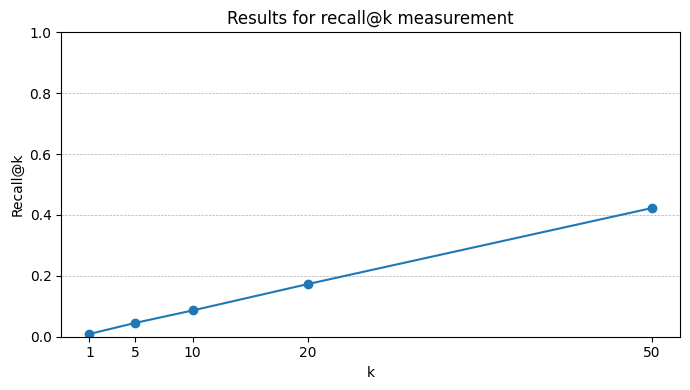

In [101]:
retrieval = {k: v for k, v in emb_results.items() if k.startswith("recall@")}

ks = [1, 5, 10, 20, 50]
recalls = [retrieval[f"recall@{k}"] for k in ks]

plt.figure(figsize=(7, 4))
plt.plot(ks, recalls, marker="o")
plt.ylim(0, 1.0)
plt.title("Results for recall@k measurement")
plt.xlabel("k")
plt.ylabel("Recall@k")
plt.xticks(ks)
plt.grid(True, which="both", axis="y", linestyle="--", linewidth=0.5)
plt.tight_layout()
plt.show()

Recall@k improves with k, but low recall at small k suggests that embeddings alone are better for candidate generation than final contradiction decision-making.

### Summary

We fine-tuned a sentence transformer (**all-MiniLM-L6-v2**) with **ContrastiveLoss** to learn embeddings where **Contradiction** pairs have high cosine similarity, and evaluated this on the test split using `BinaryClassificationEvaluator` (cosine F1).

We implemented a retrieval tool that embeds a corpus of legal sections and uses cosine similarity search to retrieve the top *k* most similar (potentially contradicting) sections for a new query section.

Finally, we applied the Stage 3 LegalBERT contradiction classifier as a post-filter to select likely true contradictions from the retrieved candidates and evaluated retrieval using Recall@k and MRR on the test contradictions.


# 5. Results and Discussion

### Summary of final models

In this project, we tackled binary contradiction detection on an English legal sentence-pair dataset. We removed the original *NotMentioned* class because all such instances had an empty premise, which would allow the model to learn a trivial shortcut. We then compared three approaches:

1) a **TF-IDF + traditional ML** approach, where the best model was **Logistic Regression (C=10)**

2) a **transformer-based classifier**, where **LegalBERT (lr=1e-5, max_len=256)** achieved the best contradiction classification performance

3) a **sentence embedding approach**, where we fine-tuned **all-MiniLM-L6-v2** with **ContrastiveLoss** and evaluated it using **cosine similarity thresholding**. In addition to pairwise evaluation, we implemented a **retrieval tool** that embeds a new section and retrieves the top k most similar sections, and then applies the (2) LegalBERT classifier as a **post-filter** to select likely true contradictions.

The main evaluation focus across tasks was **F1/precision/recall for the Contradiction class**.

### Quantitative comparison tables and graphs

In [123]:
rows = [
    {
        "Model": dummy_metrics["model"],
        "Task": "Baseline",
        "Test F1": dummy_metrics["f1_contradiction"],
        "Test Precision": dummy_metrics["precision_contradiction"],
        "Test Recall": dummy_metrics["recall_contradiction"],
        "Accuracy": dummy_metrics["accuracy"],
    },
    {
        "Model": task2final_metrics["model"],
        "Task": "Task 2",
        "Test F1":  task2final_metrics["f1_contradiction"],
        "Test Precision": task2final_metrics["precision_contradiction"],
        "Test Recall": task2final_metrics["recall_contradiction"],
        "Accuracy": task2final_metrics["accuracy"],
    },
    {
        "Model": task3final_metrics["model"],
        "Task": "Task 3",
        "Test F1":  task3final_metrics["f1_contradiction"],
        "Test Precision": task3final_metrics["precision_contradiction"],
        "Test Recall": task3final_metrics["recall_contradiction"],
        "Accuracy": task3final_metrics["accuracy"],
    },
    {
        "Model": task4final_metrics["model"],
        "Task": "Task 4",
        "Test F1":  task4final_metrics["f1_contradiction"],
        "Test Precision": task4final_metrics["precision_contradiction"],
        "Test Recall": task4final_metrics["recall_contradiction"],
        "Accuracy": task4final_metrics["accuracy"],
    },
]

df_compare_display = pd.DataFrame(rows)
metric_cols = ["Test F1", "Test Precision", "Test Recall", "Accuracy"]
for c in metric_cols:
    df_compare_display[c] = df_compare_display[c].map(lambda x: f"{x:.4f}")

display(df_compare_display)

,Model,Task,Test F1,Test Precision,Test Recall,Accuracy
0,Majority classifier,Baseline,0.0000,0.0000,0.0000,0.8056
1,Logistic Regression (C=10.0),Task 2,0.8218,0.7626,0.8909,0.9285
2,"LegalBERT (lr=1e-5, L=256)",Task 3,0.8598,0.8698,0.8500,0.9487
3,"all-MiniLM-L6-v2 (lr=2e-5, epochs=3)",Task 4,0.8306,0.8483,0.8136,0.9386


Test set performance comparison across approaches, reporting F1/precision/recall for the **Contradiction** class alongside overall accuracy.

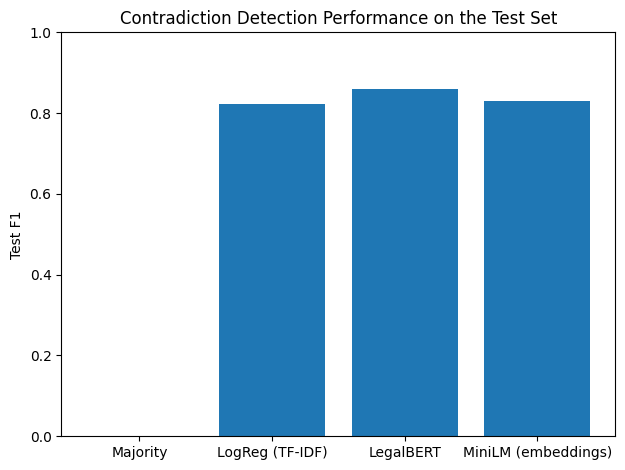

In [128]:
plot_rows = [
    {"Model": "Majority", "Test F1": dummy_metrics["f1_contradiction"]},
    {"Model": "LogReg (TF-IDF)", "Test F1": task2final_metrics["f1_contradiction"]},
    {"Model": "LegalBERT", "Test F1": task3final_metrics["f1_contradiction"]},
    {"Model": "MiniLM (embeddings)", "Test F1": task4final_metrics["f1_contradiction"]},
]

df_plot = pd.DataFrame(plot_rows)

plt.figure()
plt.bar(df_plot["Model"], df_plot["Test F1"])
plt.ylabel("Test F1")
plt.title("Contradiction Detection Performance on the Test Set")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Test set F1 score for the Contradiction class comparing the majority baseline, TF-IDF logistic regression, the LegalBERT cross-encoder classifier, and the MiniLM sentence embedding approach.

In [126]:
df_retrieval = pd.DataFrame([{
    "Retrieval variant": "Embeddings only",
    "recall@1": emb_results["recall@1"],
    "recall@5": emb_results["recall@5"],
    "recall@10": emb_results["recall@10"],
    "recall@20": emb_results["recall@20"],
    "recall@50": emb_results["recall@50"],
    "mrr@50": emb_results["mrr@50"],
    "median_best_rank": emb_results["median_best_rank"],
}])

df_retrieval_display = df_retrieval.copy()
for c in ["recall@1","recall@5","recall@10","recall@20","recall@50","mrr@50"]:
    if c in df_retrieval_display.columns:
        df_retrieval_display[c] = df_retrieval_display[c].map(lambda x: f"{x:.4f}")
for c in ["median_best_rank"]:
    if c in df_retrieval_display.columns:
        df_retrieval_display[c] = df_retrieval_display[c].map(lambda x: f"{x:.0f}")

display(df_retrieval_display)

,Retrieval variant,recall@1,recall@5,recall@10,recall@20,recall@50,mrr@50,median_best_rank
0,Embeddings only,0.0091,0.0455,0.0864,0.1727,0.4227,0.0393,25


Embeddings only retrieval results on the test set, showing how often the ground truth contradicting premise is retrieved within the top k results (**Recall@k**) and its average rank quality (**MRR@50**, median best rank).

### Qualitative examples

Below, we present three representative **LegalBERT** predictions on the test set:

- **True Positive (TP):** correctly detected *Contradiction*
- **False Positive (FP):** predicted *Contradiction* but labeled *Entailment*
- **False Negative (FN):** labeled *Contradiction* but predicted *Entailment*

In [136]:
import textwrap

def truncate_text(s, max_chars):
    s = str(s).replace("\n", " ").strip()
    if len(s) <= max_chars:
        return s
    return s[:max_chars] + " ..."

def print_example(title, hypothesis, premise, true_label, pred_label, contra_prob):
    print("\n" + "="*90)
    print(title)
    print("True Label:", true_label)
    print("Pred Label:", pred_label, f"(P(Contradiction)={contra_prob:.3f})")
    print("\nHypothesis:")
    print(textwrap.fill(str(hypothesis), width=100))
    print("\nPremise (truncated):")
    print(textwrap.fill(truncate_text(premise, 700), width=100))
    print("="*90 + "\n")

clf_dir = "./final_test"
device = "cuda" if torch.cuda.is_available() else "cpu"

clf_tokenizer = AutoTokenizer.from_pretrained(clf_dir)
clf_model = AutoModelForSequenceClassification.from_pretrained(clf_dir).to(device)
clf_model.eval()

contra_id = clf_model.config.label2id.get("Contradiction", 1)

label_map = {"Entailment": 0, "Contradiction": 1}
y_true = df_test["label"].map(label_map).astype(int).values

premises = df_test["premise"].astype(str).tolist()
hypotheses = df_test["hypothesis"].astype(str).tolist()

batch_size = 32     # makes it faster
all_probs = []
all_preds = []

with torch.no_grad():
    for i in range(0, len(df_test), batch_size):
        prem_b = premises[i:i+batch_size]
        hyp_b  = hypotheses[i:i+batch_size]

        enc = clf_tokenizer(
            prem_b, hyp_b,
            truncation=True,
            max_length=256,
            padding=True,
            return_tensors="pt"
        ).to(device)

        logits = clf_model(**enc).logits
        probs = torch.softmax(logits, dim=-1)[:, contra_id].detach().cpu().numpy()
        preds = (probs >= 0.5).astype(int)
        
        all_probs.append(probs)
        all_preds.append(preds)

all_probs = np.concatenate(all_probs)
all_preds = np.concatenate(all_preds)

df_pred = df_test.copy()
df_pred["y_true"] = y_true
df_pred["y_pred"] = all_preds
df_pred["p_contra"] = all_probs

tp = df_pred[(df_pred.y_true==1) & (df_pred.y_pred==1)].sort_values("p_contra", ascending=False).head(1)
fp = df_pred[(df_pred.y_true==0) & (df_pred.y_pred==1)].sort_values("p_contra", ascending=False).head(1)
fn = df_pred[(df_pred.y_true==1) & (df_pred.y_pred==0)].sort_values("p_contra", ascending=True).head(1)

r = tp.iloc[0]
print_example(
    "True Positive example:",
    hypothesis=r["hypothesis"],
    premise=r["premise"],
    true_label=r["label"],
    pred_label="Contradiction",
    contra_prob=r["p_contra"]
)

r = fp.iloc[0]
print_example(
    "False Positive example:",
    hypothesis=r["hypothesis"],
    premise=r["premise"],
    true_label=r["label"],
    pred_label="Contradiction",
    contra_prob=r["p_contra"]
)

r = fn.iloc[0]
print_example(
    "False Negative:",
    hypothesis=r["hypothesis"],
    premise=r["premise"],
    true_label=r["label"],
    pred_label="Entailment",
    contra_prob=r["p_contra"]
)


True Positive example:
True Label: Contradiction
Pred Label: Contradiction (P(Contradiction)=0.975)

Hypothesis:
Confidential Information shall only include technical information.

Premise (truncated):
Confidential Information includes, but is not limited to, the following types of information and
other information of a similar nature (whether or not reduced to writing): trade secrets,
inventions, drawings, file data, documentation, diagrams, specifications, know how, processes,
formulas, models, flow charts, software in various stages of development, source code, object code,
research and development procedures, research or development and test results, marketing techniques
and materials, marketing and development plans, price lists, pricing policies, business plans,
information relating to customers and/or suppliers' identities, characteristics and agreements,
financial information and p ...


False Positive example:
True Label: Entailment
Pred Label: Contradiction (P(Contradiction)

### Discussion of approaches

In this project, we evaluated three progressively more advanced approaches to contradiction detection in legal text: (1) TF-IDF + traditional classifiers, (2) a fine-tuned transformer classifier, and (3) a sentence-embedding + retrieval workflow,combined with the transformer as a post-filter. Overall, the results suggest that **traditional classifiers are already competitive**, **domain-adapted transformers provide the best contradiction classifier**, and **sentence embeddings are most useful as a candidate retrieval tool rather than a contradiction decision rule by themselves**.

**Traditional ML (TF-IDF + linear models) worked surprisingly well, because legal contradictions are often easy to spot from wording.** In legal text, contradictions are frequently signaled by very clear words like *not*, *only*, *except*, *unless*, and also by verbs like *shall / may / must*. A TF-IDF representation keeps these words very visible, and a linear model can learn that they matter. Also, this dataset contains many repeated patterns and similar sentence templates, which makes it easier for TF-IDF models to generalize. This is why Logistic Regression reached a solid contradiction F1 even though it is much simpler than transformers.

**The transformer classifier (LegalBERT) was the best model for contradiction detection.** Compared to TF-IDF, a transformer uses context, not just individual words. This matters in legal text, where meaning often depends on definitions, exceptions, and scope (for example: "Confidential Information shall only include…" vs a broad definition). Because LegalBERT was pre-trained on legal data, it likely understands legal phrasing and structure better than a general BERT model. In the experiments, LegalBERT performed better than the generic BERT on validation.

**Sentence embeddings were good for finding related clauses, but contradiction is more specific than "similar meaning".** We fine-tuned a sentence transformer so that contradiction pairs should have higher cosine similarity and entailment pairs lower cosine similarity. In the pairwise test evaluation, cosine similarity separated the labels reasonably well (good accuracy and average precision, and a moderate F1). However, retrieval is harder: one hypothesis can be similar to many premises, especially because legal clauses often repeat the same definitions and boilerplate text. Because of this, the embedding model does not always retrieve the *exact paired premise* from the dataset, even if it retrieves clauses that look relevant. This is why embedding only retrieval recall@k is not very high when we evaluate it in a strict way.


The most realistic setup for practical use is a hybrid system: embeddings for fast candidate search + a classifier to confirm real contradictions. Because we cannot run a heavy transformer classifier on every possible pair of clauses in a large document set. A more practical pipeline is:
1) use sentence embeddings to retrieve the top-k most similar clauses, then  
2) apply the fine-tuned contradiction classifier from Stage 3 as a post-filter.

**Dataset limitations affect how we interpret the results.** We removed the *NotMentioned* label because all those examples had an empty premise, which would allow a trivial shortcut. After this, our negative class is only *entailment*, not "unrelated". So our task is closer to *contradiction vs entailment* than *contradiction vs everything else*. In a real drafting scenario, most clause pairs are unrelated, so performance would likely be lower. Also, contradictions in the test set are highly repetitive, there are only 10 unique contradiction hypotheses, repeated many times. This likely makes the task easier than a more diverse dataset.

### Conclusion

In this project, we compared traditional ML models, a transformer classifier, and a sentence-embedding retrieval approach for detecting contradictions in legal text. Overall, LegalBERT was the best standalone model for contradiction classification, while TF-IDF + Logistic Regression was not far behind. Sentence embeddings worked well for retrieving related clauses, but for best results they should be combined with the LegalBERT classifier as a post-filter. In the future, we would need a dataset with real "unrelated" pairs and more diverse clause types to better match real legal drafting scenarios.